# Minggu 3 — Hasil dan Analisis

**Tema: Engine Sound Classification.** Evaluasi QUANT + ExtraTrees, statistik–Welch48 + ExtraTrees, dan QUANT + Ridge pada seluruh FordA melalui lima fold yang sama.

**Status:** notebook disiapkan dan implementasinya diuji pada CPU lokal. Angka dalam tabel berikut berasal dari run notebook ini setelah dijalankan. Hasil lokal tidak disalin sebagai hasil Colab.

Pilih runtime **CPU**, lalu jalankan dari atas. Dataset, paket, fitur, model, dan prediksi diperiksa sebelum cache dipakai. Hasil disimpan terpisah dari M1 dan M2.

## 1. Protokol yang dipakai

| Komponen | Ketentuan |
|---|---|
| Data | Seluruh 4.921 kasus, panjang 500, label −1/+1 |
| Fold | StratifiedKFold 5, shuffle=True, seed 42; indeks sama untuk semua metode |
| Baseline | QUANT depth 6/div 4, ExtraTrees 200, entropy, max_features 0,1, seed 0 |
| Pembanding fitur | Statistik–Welch48; ExtraTrees sama |
| Pembanding classifier | QUANT, StandardScaler, RidgeCV dengan 10 alpha 10^-3…10^3 |
| Metrik utama | Macro-F1, ditetapkan sebelum hasil M3 diperiksa |
| Statistik | Paired t-test dua sisi, dua pembanding terhadap baseline, koreksi Holm |
| Kurva learning | Diagnostik di dalam train fold pertama, bukan rata-rata lima fold |

M3 menggabungkan train dan test resmi ke dalam pool CV. Kasus test resmi dapat menjadi data train suatu fold. Ini **analisis lanjutan dengan protokol berbeda** dari holdout M2 maupun 30 resample M1. Angkanya tidak dibandingkan langsung seolah protokol identik.

Scaler hanya fit pada train fold dan alpha dipilih di train fold. Fitur QUANT/Welch tidak mempelajari statistik antarkasus atau label, sehingga dapat dicache sekali. Identitas mesin/sesi tidak tersedia; stratifikasi kelas tidak menjamin generalisasi ke mesin baru.

In [1]:
from pathlib import Path
import os,sys,json,csv,subprocess,shutil
from google.colab import drive
if not (os.path.ismount('/content/drive') and Path('/content/drive/MyDrive').is_dir()):
    drive.mount('/content/drive')
else:
    print('Google Drive sudah terhubung.')
PROJECT=Path('/content/dsp_quant_m3')
DRIVE=Path('/content/drive/MyDrive/dsp_quant_forda')
DATA=DRIVE/'data'
RUN=DRIVE/'runs/m3_stratified5fold_seed42'
DEPS=Path('/content/quant_dependencies')
M1_FEATURES=DRIVE/'runs/quant_original_method_30resamples/features.npy'
for folder in [PROJECT,DRIVE,DATA,RUN,DEPS]:folder.mkdir(parents=True,exist_ok=True)
print('Cache M1:', 'ada; akan diverifikasi' if M1_FEATURES.is_file() else 'belum ada; fitur akan dihitung')
print('Folder hasil M3:',RUN)
if (RUN/'run_status.json').is_file():print('Status tersimpan:',json.loads((RUN/'run_status.json').read_text()))

Mounted at /content/drive
Cache M1: ada; akan diverifikasi
Folder hasil M3: /content/drive/MyDrive/dsp_quant_forda/runs/m3_stratified5fold_seed42


In [2]:
#@title Menyiapkan sumber eksperimen M3 dan paket CPU
FILES = {
'run_analysis.py':'"""M3: complete FordA, paired five-fold comparison, resumable CPU experiments."""\nfrom __future__ import annotations\nimport argparse,csv,gc,hashlib,json,os,time\nfrom pathlib import Path\nimport numpy as np\nimport baseline_runner as base\nimport comparison_methods as methods\n\nBASE=Path(__file__).resolve().parent\nMETHODS=methods.METHODS\nLABELS=[\'QUANT + ExtraTrees\',\'Welch48 + ExtraTrees\',\'QUANT + Ridge\']\nCONFIG={\'scope\':\'M3_pooled_4921_cases_not_official_holdout\',\'n_splits\':5,\'shuffle\':True,\'split_seed\':42,\n \'methods\':methods.CONFIG,\'primary_metric\':\'macro_f1\',\'classifier_seed\':0,\'alpha\':.05,\n \'paired_test\':\'two-sided ttest_rel(comparator,baseline), exploratory correlated CV folds\',\n \'multiplicity\':\'Holm two prespecified comparisons\',\'std_ddof\':1,\n \'learning_curve\':{\'diagnostic_outer_fold\':1,\'inner_validation_fraction\':.2,\'seed\':1042,\'fractions\':[.25,.5,.75,1.]},\n \'error_examples_method\':\'Welch48_ExtraTrees\',\'error_examples\':\'first 2 FP and first 2 FN by global index, if available\'}\n\ndef make_folds(y):\n    from sklearn.model_selection import StratifiedKFold\n    out=list(StratifiedKFold(5,shuffle=True,random_state=42).split(np.zeros(len(y)),y))\n    seen=np.zeros(len(y),int)\n    for tr,te in out:\n        if np.intersect1d(tr,te).size or len(tr)+len(te)!=len(y):raise ValueError(\'Fold overlap.\')\n        seen[te]+=1\n    if not np.all(seen==1):raise ValueError(\'Each case must be held out exactly once.\')\n    return out\n\ndef holm_adjust(p):\n    p=np.asarray(p,float)\n    if p.ndim!=1 or not np.isfinite(p).all() or ((p<0)|(p>1)).any():raise ValueError(\'Invalid p-values.\')\n    order=np.argsort(p);adjusted=np.maximum.accumulate((len(p)-np.arange(len(p)))*p[order]);out=np.empty_like(p)\n    out[order]=np.minimum(adjusted,1.);return out.tolist()\n\ndef paired_statistics(baseline,comparator):\n    from scipy.stats import ttest_rel\n    b,c=np.asarray(baseline,float),np.asarray(comparator,float)\n    if b.shape!=(5,) or c.shape!=(5,) or not np.isfinite(np.r_[b,c]).all():raise ValueError(\'Exactly five complete paired folds required.\')\n    delta=c-b;mean=float(delta.mean());sd=float(delta.std(ddof=1))\n    result={\'n_pairs\':5,\'df\':4,\'mean_delta\':mean,\'delta_std\':sd,\'direction\':\'comparator_minus_baseline\'}\n    if sd<1e-14:\n        zero=abs(mean)<1e-14\n        return dict(result,t_statistic=0. if zero else None,p_raw=1. if zero else None,\n                    ci95_low=0. if zero else None,ci95_high=0. if zero else None,\n                    test_status=\'identical_scores\' if zero else \'undefined_zero_variance_difference\')\n    t=ttest_rel(c,b,alternative=\'two-sided\',nan_policy=\'raise\');ci=t.confidence_interval(.95)\n    return dict(result,t_statistic=float(t.statistic),p_raw=float(t.pvalue),ci95_low=float(ci.low),ci95_high=float(ci.high),test_status=\'computed\')\n\ndef assemble_oof(parts,y):\n    n=len(y);seen=np.zeros(n,int);pred=np.empty(n,np.int64);score=np.empty(n,float);fold=np.empty(n,np.int64)\n    for z in parts:\n        idx=np.asarray(z[\'test_indices\'],int)\n        if len(np.unique(idx))!=len(idx) or (idx<0).any() or (idx>=n).any():raise ValueError(\'Invalid held-out indices.\')\n        if not np.array_equal(np.asarray(z[\'y_true\']),y[idx]):raise ValueError(\'Label/index mismatch.\')\n        if not (len(idx)==len(z[\'y_pred\'])==len(z[\'score\'])) or not np.isfinite(z[\'score\']).all():raise ValueError(\'Invalid predictions.\')\n        seen[idx]+=1;pred[idx]=z[\'y_pred\'];score[idx]=z[\'score\'];fold[idx]=z[\'fold\']\n    if not np.all(seen==1):raise ValueError(\'Missing or duplicate OOF predictions.\')\n    return {\'y_true\':y,\'y_pred\':pred,\'score\':score,\'fold\':fold,\'global_indices\':np.arange(n)}\n\ndef verify_cached(row,identity,model,predictions):\n    if row[\'identity\']!=identity:raise ValueError(\'Cache identity changed; use a new output folder.\')\n    for path,key in [(model,\'model_sha256\'),(predictions,\'predictions_sha256\')]:\n        if not Path(path).is_file() or base.sha(path)!=row[key]:raise ValueError(\'Cache incomplete or corrupt: \'+str(path))\n    return True\n\ndef save_npz(path,**arrays):\n    path=Path(path);tmp=path.with_name(path.name+\'.partial\')\n    with tmp.open(\'wb\') as f:np.savez_compressed(f,**arrays)\n    os.replace(tmp,path)\n\ndef write_csv(path,rows,fields):\n    path=Path(path);tmp=path.with_name(path.name+\'.partial\')\n    with tmp.open(\'w\',newline=\'\',encoding=\'utf-8\') as f:\n        writer=csv.DictWriter(f,fields,extrasaction=\'ignore\');writer.writeheader();writer.writerows(rows)\n    os.replace(tmp,path)\n\ndef signal_audit(X,y,folds):\n    groups={}\n    for i,x in enumerate(X):groups.setdefault(hashlib.sha256(x.tobytes()).hexdigest(),[]).append(i)\n    duplicate=[v for v in groups.values() if len(v)>1]\n    fold_id=np.empty(len(y),int)\n    for i,(_,te) in enumerate(folds):fold_id[te]=i+1\n    return {\'n_cases\':len(y),\'signal_length\':X.shape[1],\'all_cases_used\':True,\'original_train\':3601,\'original_test\':1320,\n       \'archive_sha256\':base.ARCHIVE_SHA,\'exact_duplicate_groups\':duplicate,\n       \'cross_fold_duplicate_groups\':[g for g in duplicate if len(np.unique(fold_id[g]))>1],\n       \'conflicting_label_duplicate_groups\':[g for g in duplicate if len(np.unique(y[g]))>1],\n       \'limitations\':\'Exact duplicate audit only; no engine/session grouping metadata. Original official test is pooled for M3.\'}\n\ndef prepare_features(X,y,out,m1_features,env,identity):\n    import torch\n    quant_path=Path(m1_features) if m1_features else None\n    reused=False;t=time.perf_counter()\n    if quant_path and quant_path.is_file():\n        folder=quant_path.parent;meta=base.read(folder/\'features_meta.json\');config=base.read(folder/\'config.json\');oldenv=base.read(folder/\'environment.json\')\n        if config!=base.CONFIG or oldenv[\'packages\']!=env[\'packages\'] or oldenv[\'source_lock\']!=env[\'source_lock\'] or base.sha(quant_path)!=meta[\'sha256\']:\n            raise ValueError(\'M1 feature cache incompatible. Set M1_FEATURES=None to recompute without changing the method.\')\n        reused=True\n    else:\n        quant_path=out/\'quant_features.npy\';meta_path=out/\'quant_features_meta.json\'\n        if quant_path.exists() and meta_path.exists():\n            meta=base.read(meta_path)\n            if meta[\'identity\']!=identity or base.sha(quant_path)!=meta[\'sha256\']:raise ValueError(\'M3 feature cache invalid.\')\n            reused=True\n        else:\n            with torch.no_grad():\n                Q=base.backend()(depth=6,div=4).fit_transform(torch.from_numpy(X[:,None,:]),torch.from_numpy(y)).numpy()\n            tmp=quant_path.with_name(quant_path.name+\'.partial\')\n            with tmp.open(\'wb\') as f:np.save(f,Q)\n            os.replace(tmp,quant_path);base.save(meta_path,{\'identity\':identity,\'sha256\':base.sha(quant_path),\'shape\':list(Q.shape)})\n            del Q\n    Q=np.load(quant_path,mmap_mode=\'r\');quant_seconds=time.perf_counter()-t\n    if Q.shape!=(4921,4469) or not np.isfinite(Q).all():raise ValueError(\'QUANT dimensions/content invalid.\')\n    h_path=out/\'welch48.npy\';h_meta=out/\'welch48_meta.json\';t=time.perf_counter()\n    if h_path.exists() and h_meta.exists():\n        hm=base.read(h_meta)\n        if hm[\'identity\']!=identity or hm[\'sha256\']!=base.sha(h_path):raise ValueError(\'Welch cache invalid.\')\n    else:\n        H=methods.compact_features(X);tmp=h_path.with_name(h_path.name+\'.partial\')\n        with tmp.open(\'wb\') as f:np.save(f,H)\n        os.replace(tmp,h_path);base.save(h_meta,{\'identity\':identity,\'sha256\':base.sha(h_path)})\n    H=np.load(h_path,mmap_mode=\'r\')\n    if H.shape!=(4921,48) or not np.isfinite(H).all():raise ValueError(\'Welch features invalid.\')\n    audit={\'quant_shape\':list(Q.shape),\'welch_shape\':list(H.shape),\'quant_cache_reused\':reused,\n       \'quant_seconds_this_run\':quant_seconds,\'welch_seconds_this_run\':time.perf_counter()-t,\n       \'quant_sha256\':base.sha(quant_path),\'welch_sha256\':base.sha(h_path),\n       \'sample_independent_transform\':True,\'timing_note\':\'Cache reads are not fresh extraction timings.\'}\n    base.save(out/\'feature_audit.json\',audit)\n    return Q,H\n\ndef fit_job(name,F,y,tr,te,path,identity,fold):\n    import joblib\n    from sklearn.metrics import f1_score,recall_score\n    path=Path(path);path.mkdir(parents=True,exist_ok=True)\n    mf,pf,rf=path/\'model.joblib\',path/\'predictions.npz\',path/\'metrics.json\'\n    split_hash=base.digest({\'train\':tr.tolist(),\'test\':te.tolist()})\n    if rf.exists():\n        row=base.read(rf);verify_cached(row,identity,mf,pf)\n        if row[\'split_sha256\']!=split_hash or row[\'method\']!=name:raise ValueError(\'Cached split/method mismatch.\')\n        with np.load(pf) as z:\n            if not np.array_equal(z[\'test_indices\'],te) or not np.array_equal(z[\'y_true\'],y[te]):raise ValueError(\'Cached predictions have wrong cases.\')\n            measured=base.metrics(z[\'y_true\'],z[\'y_pred\'],z[\'score\'])\n            for key,value in measured.items():\n                if not np.allclose(row[key],value,rtol=0,atol=1e-12):raise ValueError(\'Cached metrics disagree with predictions: \'+key)\n        print(f\'Fold {fold} / {name}: cache valid\',flush=True);return row,True\n    start=time.perf_counter();est=methods.model(name);est.fit(F[tr],y[tr]);fit=time.perf_counter()-start\n    start=time.perf_counter();pred=est.predict(F[te]);score=methods.scores(est,F[te]);predict=time.perf_counter()-start\n    save_npz(pf,y_true=y[te],y_pred=pred,score=score,test_indices=te)\n    temp=mf.with_name(mf.name+\'.partial\');joblib.dump(est,temp);os.replace(temp,mf)\n    f1=f1_score(y[te],pred,labels=[-1,1],average=None,zero_division=0);rec=recall_score(y[te],pred,labels=[-1,1],average=None,zero_division=0)\n    row={\'identity\':identity,\'method\':name,\'fold\':fold,\'n_train\':len(tr),\'n_test\':len(te),\'features\':F.shape[1],\n       \'split_sha256\':split_hash,**base.metrics(y[te],pred,score),\'f1_minus1\':float(f1[0]),\'f1_plus1\':float(f1[1]),\n       \'recall_minus1\':float(rec[0]),\'recall_plus1\':float(rec[1]),\'train_macro_f1\':float(f1_score(y[tr],est.predict(F[tr]),average=\'macro\')),\n       \'fit_seconds\':fit,\'predict_seconds\':predict,\'score_type\':\'decision_function\' if name.endswith(\'Ridge\') else \'probability\',\n       \'alpha\':float(est[-1].alpha_) if name.endswith(\'Ridge\') else None,\n       \'model_sha256\':base.sha(mf),\'predictions_sha256\':base.sha(pf)}\n    base.save(rf,row);del est;gc.collect()\n    print(f\'Fold {fold} / {name}: F1={row["macro_f1"]:.6f}, AUC={row["roc_auc"]:.6f}, fit={fit:.2f}s\',flush=True)\n    return row,False\n\ndef summary_and_tests(rows):\n    summary=[];paired=[]\n    for name in METHODS:\n        own=sorted([r for r in rows if r[\'method\']==name],key=lambda r:r[\'fold\'])\n        if [r[\'fold\'] for r in own]!=list(range(1,6)):raise ValueError(\'Exactly one record per method/fold required.\')\n        row={\'method\':name,\'folds\':5}\n        for metric in [\'accuracy\',\'balanced_accuracy\',\'macro_f1\',\'roc_auc\',\'fit_seconds\',\'predict_seconds\',\'f1_minus1\',\'f1_plus1\']:\n            values=np.array([r[metric] for r in own]);row[metric+\'_mean\']=float(values.mean());row[metric+\'_std\']=float(values.std(ddof=1))\n        summary.append(row)\n    b=sorted([r for r in rows if r[\'method\']==METHODS[0]],key=lambda r:r[\'fold\'])\n    for name in METHODS[1:]:\n        p=sorted([r for r in rows if r[\'method\']==name],key=lambda r:r[\'fold\'])\n        if [r[\'split_sha256\'] for r in p]!=[r[\'split_sha256\'] for r in b]:raise ValueError(\'Paired folds do not share indices.\')\n        paired.append({\'baseline\':METHODS[0],\'comparator\':name,\'metric\':\'macro_f1\',**paired_statistics([r[\'macro_f1\'] for r in b],[r[\'macro_f1\'] for r in p])})\n    # A non-estimable test remains in the family with p=1 for adjustment, while its reported p stays null.\n    adjusted=holm_adjust([r[\'p_raw\'] if r[\'p_raw\'] is not None else 1. for r in paired])\n    for row,p in zip(paired,adjusted):\n        row[\'p_holm\']=p if row[\'p_raw\'] is not None else None\n        row[\'significant_holm_005\']=row[\'p_holm\'] is not None and p<.05\n        row[\'interpretation\']=(\'different_mean_in_exploratory_test\' if row[\'significant_holm_005\'] else \'no_significant_difference_established\')\n    return summary,paired\n\ndef error_analysis(out,X,y,oofs):\n    all_errors=[];summary=[]\n    for name,z in oofs.items():\n        pred=z[\'y_pred\'];fp=np.flatnonzero((y==-1)&(pred==1));fn=np.flatnonzero((y==1)&(pred==-1))\n        summary.append({\'method\':name,\'false_positive\':len(fp),\'false_negative\':len(fn),\'total_errors\':len(fp)+len(fn),\'positive_label\':1})\n        for i in np.flatnonzero(pred!=y):\n            all_errors.append({\'method\':name,\'global_index\':int(i),\'source_file\':\'FordA_TRAIN.ts\' if i<3601 else \'FordA_TEST.ts\',\n              \'source_case_1based\':int(i+1 if i<3601 else i-3601+1),\'fold\':int(z[\'fold\'][i]),\'y_true\':int(y[i]),\'y_pred\':int(pred[i]),\n              \'score\':float(z[\'score\'][i]),\'error_type\':\'FP\' if y[i]==-1 else \'FN\'})\n    write_csv(out/\'errors.csv\',all_errors,[\'method\',\'global_index\',\'source_file\',\'source_case_1based\',\'fold\',\'y_true\',\'y_pred\',\'score\',\'error_type\'])\n    write_csv(out/\'error_summary.csv\',summary,[\'method\',\'false_positive\',\'false_negative\',\'total_errors\',\'positive_label\'])\n    subset=[]\n    for kind in [\'FP\',\'FN\']:subset.extend([e for e in all_errors if e[\'method\']==CONFIG[\'error_examples_method\'] and e[\'error_type\']==kind][:2])\n    base.save(out/\'error_examples.json\',{\'selection\':CONFIG[\'error_examples\'],\'examples\':subset,\'caution\':\'Sample descriptions do not identify physical defect causes.\'})\n    return summary\n\ndef diagnostic_learning(Q,H,y,train,test,out,identity):\n    from sklearn.model_selection import train_test_split,StratifiedShuffleSplit\n    inner,val=train_test_split(train,test_size=.2,stratify=y[train],random_state=1042)\n    records=[];new=cached=0\n    for frac in [.25,.5,.75,1.]:\n        if frac==1.:sub=inner\n        else:\n            a,_=next(StratifiedShuffleSplit(n_splits=1,train_size=frac,random_state=1042).split(inner,y[inner]));sub=inner[a]\n        if np.intersect1d(np.r_[sub,val],test).size:raise ValueError(\'Outer test leaked into learning curve.\')\n        for name in METHODS:\n            F=H if name.startswith(\'Welch\') else Q\n            row,used=fit_job(name,F,y,sub,val,out/\'learning_jobs\'/f\'n{len(sub)}\'/name,identity,1)\n            cached+=int(used);new+=int(not used)\n            records.append({\'method\':name,\'n_train\':len(sub),\'n_validation\':len(val),\'train_macro_f1\':row[\'train_macro_f1\'],\'validation_macro_f1\':row[\'macro_f1\']})\n    base.save(out/\'learning_curves.json\',{\'identity\':identity,\'diagnostic_outer_fold\':1,\'validation_indices\':val.tolist(),\n       \'excluded_outer_test_indices\':test.tolist(),\'records\':records,\'used_for_parameter_selection\':False})\n    return new,cached\n\ndef run(root,out,m1_features=None):\n    import torch\n    from threadpoolctl import threadpool_limits\n    out=Path(out);out.mkdir(parents=True,exist_ok=True);torch.set_num_threads(2)\n    env=base.environment();env[\'m3_source_sha256\']=base.sha(__file__);env[\'m2_methods_sha256\']=base.sha(BASE/\'comparison_methods.py\')\n    identity=base.digest({\'config\':CONFIG,\'environment\':env,\'archive\':base.ARCHIVE_SHA})\n    if (out/\'identity.json\').exists() and base.read(out/\'identity.json\')[\'identity\']!=identity:raise ValueError(\'Run identity changed. Use another RUN folder; do not mix caches.\')\n    base.save(out/\'identity.json\',{\'identity\':identity});base.save(out/\'config.json\',CONFIG);base.save(out/\'environment.json\',env)\n    (out/\'requirements_actual.txt\').write_text(\'\\n\'.join(f\'{k}=={v}\' for k,v in env[\'packages\'].items())+\'\\n\')\n    base.save(out/\'run_status.json\',{\'status\':\'running\',\'completed_fold_jobs\':0,\'total_fold_jobs\':15,\'complete\':False})\n    Xtr,ytr,Xte,yte=base.data(root);X=np.r_[Xtr,Xte];y=np.r_[ytr,yte];folds=make_folds(y)\n    audit=signal_audit(X,y,folds);base.save(out/\'data_audit.json\',audit)\n    if audit[\'cross_fold_duplicate_groups\']:print(\'Warning: exact duplicate signals occur across folds; inspect data_audit.json.\',flush=True)\n    base.save(out/\'folds.json\',{\'seed\':42,\'pool\':\'official train + official test\',\'shared_by_all_methods\':True,\n       \'folds\':[{\'fold\':i+1,\'train_indices\':tr.tolist(),\'test_indices\':te.tolist()} for i,(tr,te) in enumerate(folds)]})\n    new=cached=0\n    with threadpool_limits(limits=2):\n        Q,H=prepare_features(X,y,out,m1_features,env,identity);rows=[];parts={n:[] for n in METHODS}\n        for fold,(tr,te) in enumerate(folds,1):\n            for name in METHODS:\n                path=out/\'folds\'/f\'{fold:02d}\'/name;F=H if name.startswith(\'Welch\') else Q\n                row,used=fit_job(name,F,y,tr,te,path,identity,fold);rows.append(row);cached+=int(used);new+=int(not used)\n                with np.load(path/\'predictions.npz\') as z:parts[name].append({k:z[k].copy() for k in z.files}|{\'fold\':fold})\n                base.save(out/\'run_status.json\',{\'status\':\'running\',\'completed_fold_jobs\':len(rows),\'total_fold_jobs\':15,\'complete\':False})\n        oofs={name:assemble_oof(parts[name],y) for name in METHODS}\n        for name,z in oofs.items():save_npz(out/(name+\'_oof.npz\'),**z)\n        summary,paired=summary_and_tests(rows)\n        errors=error_analysis(out,X,y,oofs)\n        n,c=diagnostic_learning(Q,H,y,*folds[0],out,identity);new+=n;cached+=c\n    write_csv(out/\'fold_metrics.csv\',rows,[\'method\',\'fold\',\'n_train\',\'n_test\',\'accuracy\',\'balanced_accuracy\',\'macro_f1\',\'roc_auc\',\'f1_minus1\',\'f1_plus1\',\'fit_seconds\',\'predict_seconds\',\'alpha\'])\n    fields=[\'method\',\'folds\']+[m+s for m in [\'accuracy\',\'balanced_accuracy\',\'macro_f1\',\'roc_auc\',\'fit_seconds\',\'predict_seconds\',\'f1_minus1\',\'f1_plus1\'] for s in [\'_mean\',\'_std\']]\n    write_csv(out/\'summary.csv\',summary,fields)\n    write_csv(out/\'paired_tests.csv\',paired,[\'baseline\',\'comparator\',\'metric\',\'n_pairs\',\'df\',\'mean_delta\',\'delta_std\',\'t_statistic\',\'p_raw\',\'p_holm\',\'ci95_low\',\'ci95_high\',\'significant_holm_005\',\'test_status\',\'interpretation\'])\n    base.save(out/\'results.json\',{\'summary\':summary,\'paired_tests\':paired,\'error_summary\':errors,\'complete\':True,\'folds\':5,\'scope\':CONFIG[\'scope\'],\n       \'statistics_limitations\':\'Exploratory paired t-tests with five correlated CV folds. Holm corrects two comparisons, not fold dependence. No external confirmation.\'})\n    plot(out,X)\n    base.save(out/\'run_status.json\',{\'status\':\'complete\',\'complete\':True,\'completed_fold_jobs\':15,\'total_fold_jobs\':15,\n       \'learning_jobs\':12,\'new_fits_this_invocation\':new,\'cached_fits_this_invocation\':cached,\'OOF_cases_per_method\':len(y)})\n    print(json.dumps({\'complete\':True,\'summary\':summary,\'paired_tests\':paired,\'new_fits\':new,\'cached_fits\':cached},indent=2),flush=True)\n\ndef plot(out,X):\n    import matplotlib;matplotlib.use(\'Agg\')\n    import matplotlib.pyplot as plt\n    from sklearn.metrics import ConfusionMatrixDisplay,roc_curve,auc\n    from scipy.signal import welch\n    out=Path(out);results=base.read(out/\'results.json\');rows=list(csv.DictReader((out/\'fold_metrics.csv\').open()))\n    plt.rcParams.update({\'font.size\':10,\'axes.labelcolor\':\'black\',\'text.color\':\'black\',\'axes.edgecolor\':\'black\'})\n    fig,axes=plt.subplots(1,3,figsize=(13,4))\n    for ax,key,title in zip(axes,[\'balanced_accuracy\',\'macro_f1\',\'roc_auc\'],[\'Macro-Accuracy\',\'Macro-F1\',\'ROC-AUC\']):\n        vals=[[float(r[key]) for r in rows if r[\'method\']==n] for n in METHODS]\n        ax.boxplot(vals,tick_labels=[\'QUANT+ET\',\'Welch48+ET\',\'QUANT+Ridge\'],medianprops={\'color\':\'black\'})\n        for i,v in enumerate(vals,1):ax.plot(np.full(len(v),i),v,\'o\',color=\'gray\',markersize=4)\n        ax.set_title(title);ax.tick_params(axis=\'x\',labelrotation=12);ax.set_ylabel(\'Score (0–1)\')\n    fig.tight_layout();fig.savefig(out/\'boxplot_metrics.png\',dpi=170);plt.close(fig)\n    fig,axes=plt.subplots(1,2,figsize=(10,4))\n    for ax,key,label in zip(axes,[\'f1_minus1\',\'f1_plus1\'],[-1,1]):\n        ax.boxplot([[float(r[key]) for r in rows if r[\'method\']==n] for n in METHODS],tick_labels=[\'QUANT+ET\',\'Welch48+ET\',\'QUANT+Ridge\'],medianprops={\'color\':\'black\'})\n        ax.set(title=f\'F1 kelas {label}\',ylabel=\'F1 (0–1)\');ax.tick_params(axis=\'x\',labelrotation=12)\n    fig.tight_layout();fig.savefig(out/\'boxplot_per_class.png\',dpi=170);plt.close(fig)\n    fig,axes=plt.subplots(1,3,figsize=(13,4));figroc,ar=plt.subplots(1,3,figsize=(14,4))\n    for i,(name,label) in enumerate(zip(METHODS,LABELS)):\n        with np.load(out/(name+\'_oof.npz\')) as z:y,p,s,f=z[\'y_true\'],z[\'y_pred\'],z[\'score\'],z[\'fold\']\n        ConfusionMatrixDisplay.from_predictions(y,p,labels=[-1,1],cmap=\'Greys\',colorbar=False,ax=axes[i]);axes[i].set_title(label,fontsize=11)\n        grid=np.linspace(0,1,201);interpolated=[];aucs=[]\n        for fold in range(1,6):\n            a,b,_=roc_curve(y[f==fold],s[f==fold],pos_label=1);ar[i].plot(a,b,color=\'gray\',alpha=.5,linewidth=.8)\n            line=np.interp(grid,a,b);line[0]=0;interpolated.append(line);aucs.append(auc(a,b))\n        mean=np.mean(interpolated,axis=0);mean[-1]=1\n        ar[i].plot(grid,mean,color=\'black\',label=f\'Mean fold AUC {np.mean(aucs):.4f} ± {np.std(aucs,ddof=1):.4f}\')\n        ar[i].set(title=label,xlabel=\'False Positive Rate\',ylabel=\'True Positive Rate\',xlim=(0,1),ylim=(0,1.01));ar[i].legend(fontsize=8,loc=\'lower right\')\n    fig.tight_layout();fig.savefig(out/\'confusion_oof.png\',dpi=170);figroc.tight_layout();figroc.savefig(out/\'roc_multifold.png\',dpi=170);plt.close(\'all\')\n    curves=base.read(out/\'learning_curves.json\')[\'records\'];fig,axes=plt.subplots(1,3,figsize=(13,4))\n    for ax,name,label in zip(axes,METHODS,LABELS):\n        pts=[r for r in curves if r[\'method\']==name]\n        ax.plot([r[\'n_train\'] for r in pts],[r[\'train_macro_f1\'] for r in pts],\'o-\',color=\'black\',label=\'Train\')\n        ax.plot([r[\'n_train\'] for r in pts],[r[\'validation_macro_f1\'] for r in pts],\'s--\',color=\'gray\',label=\'Inner validation\')\n        ax.set(title=label,xlabel=\'Training cases (outer fold 1 only)\',ylabel=\'Macro-F1\',ylim=(.8,1.01));ax.legend(fontsize=9)\n    fig.tight_layout();fig.savefig(out/\'learning_curve_internal.png\',dpi=170);plt.close(fig)\n    examples=base.read(out/\'error_examples.json\')[\'examples\']\n    if examples:\n        fig,axes=plt.subplots(len(examples),2,figsize=(12,2.4*len(examples)),squeeze=False)\n        for pair,e in zip(axes,examples):\n            x=X[e[\'global_index\']];f,p=welch(x,fs=1.,window=\'hann\',nperseg=256,noverlap=128,nfft=256,detrend=\'constant\')\n            pair[0].plot(x,color=\'black\',linewidth=.7);pair[0].set(title=f"{e[\'error_type\']} / index {e[\'global_index\']} / fold {e[\'fold\']} / true {e[\'y_true\']} predicted {e[\'y_pred\']}",xlabel=\'Sample index\',ylabel=\'Amplitude\')\n            pair[1].plot(f,p/max(p.sum(),1e-12),color=\'black\');pair[1].set(xlabel=\'Normalized frequency (cycles/sample)\',ylabel=\'Relative PSD bin mass\')\n        fig.tight_layout();fig.savefig(out/\'error_examples.png\',dpi=160);plt.close(fig)\n\nif __name__==\'__main__\':\n    parser=argparse.ArgumentParser();parser.add_argument(\'--root\',type=Path,required=True);parser.add_argument(\'--out\',type=Path,required=True);parser.add_argument(\'--m1-features\',type=Path)\n    args=parser.parse_args();run(args.root,args.out,args.m1_features)\n',
'comparison_methods.py':'"""M2 controlled comparisons. Full FordA original split; training-only learning curves."""\nfrom __future__ import annotations\nimport argparse,csv,hashlib,json,os,time\nfrom pathlib import Path\nimport numpy as np\nfrom scipy.signal import welch\nfrom scipy.stats import skew,kurtosis\nimport baseline_runner as baseline\n\nBASE=Path(__file__).resolve().parent\nMETHODS=[\'QUANT_ExtraTrees\',\'Welch48_ExtraTrees\',\'QUANT_Ridge\']\nCONFIG={\'scope\':\'M2_original_split_not_M3_5fold\',\'train\':3601,\'test\':1320,\'length\':500,\n        \'seed\':0,\'feature_comparator\':{\'time_features\':8,\'spectral_features\':8,\'relative_bands\':32,\'total\':48,\n          \'welch\':{\'fs\':1.0,\'units\':\'cycles_per_sample_not_physical_Hz\',\'window\':\'hann\',\'nperseg\':256,\'noverlap\':128,\'nfft\':256,\'detrend\':\'constant\'}},\n        \'ExtraTrees\':{\'n_estimators\':200,\'max_features\':.1,\'criterion\':\'entropy\',\'bootstrap\':False,\'random_state\':0,\'n_jobs\':2},\n        \'Ridge\':{\'scaler\':\'StandardScaler_fit_train\',\'alphas\':np.logspace(-3,3,10).tolist(),\'cv\':None,\'selection\':\'efficient_LOOCV_negative_mean_squared_error_training_only\'},\n        \'learning_curve\':{\'main_train_only\':True,\'validation_fraction\':.2,\'random_state\':42,\'fractions\':[.25,.5,.75,1.]}}\n\n\ndef compact_features(X):\n    X=np.asarray(X,dtype=np.float64)\n    if X.ndim!=2 or X.shape[1]!=500 or not np.isfinite(X).all():raise ValueError(\'Input must be finite N x500.\')\n    eps=1e-12;absx=np.abs(X);peak=absx.max(axis=1);rms=np.sqrt(np.mean(X**2,axis=1));meanabs=absx.mean(axis=1)\n    with np.errstate(invalid=\'ignore\',divide=\'ignore\'):\n        temporal=np.column_stack([skew(X,axis=1,bias=False),kurtosis(X,axis=1,fisher=True,bias=False),\n           peak/np.maximum(rms,eps),peak/np.maximum(meanabs,eps),rms/np.maximum(meanabs,eps),\n           peak/np.maximum(np.mean(np.sqrt(absx),axis=1)**2,eps),np.mean(np.diff(np.signbit(X),axis=1),axis=1),\n           np.sqrt(np.mean(np.diff(X,axis=1)**2,axis=1))])\n    f,p=welch(X,fs=1.,window=\'hann\',nperseg=256,noverlap=128,nfft=256,detrend=\'constant\',axis=1,scaling=\'density\')\n    total=p.sum(axis=1,keepdims=True);q=p/np.maximum(total,eps);freq=f/.5\n    centroid=(q*freq).sum(axis=1);center=freq[None,:]-centroid[:,None];bw=np.sqrt((q*center**2).sum(axis=1))\n    spec_skew=(q*center**3).sum(axis=1)/np.maximum(bw**3,eps)\n    spec_kurt=(q*center**4).sum(axis=1)/np.maximum(bw**4,eps)-3\n    flat=np.exp(np.mean(np.log(np.maximum(p,eps)),axis=1))/np.maximum(p.mean(axis=1),eps)\n    entropy=-(q*np.log(np.maximum(q,eps))).sum(axis=1)/np.log(len(f))\n    roll=freq[np.argmax(np.cumsum(q,axis=1)>=.85,axis=1)];peakfreq=freq[np.argmax(p,axis=1)]\n    spectral=np.column_stack([centroid,bw,spec_skew,spec_kurt,flat,entropy,roll,peakfreq])\n    edges=np.linspace(0,.5,33)\n    bands=np.column_stack([q[:,(f>=a)&((f<b) if i<31 else (f<=b))].sum(axis=1) for i,(a,b) in enumerate(zip(edges[:-1],edges[1:]))])\n    F=np.nan_to_num(np.column_stack([temporal,spectral,bands]),nan=0.,posinf=0.,neginf=0.)\n    F[total[:,0]<=eps]=0\n    assert F.shape==(len(X),48) and np.isfinite(F).all()\n    return F.astype(np.float32)\n\n\ndef model(name):\n    from sklearn.ensemble import ExtraTreesClassifier\n    from sklearn.linear_model import RidgeClassifierCV\n    from sklearn.pipeline import make_pipeline\n    from sklearn.preprocessing import StandardScaler\n    if name.endswith(\'ExtraTrees\'):return ExtraTreesClassifier(**CONFIG[\'ExtraTrees\'])\n    return make_pipeline(StandardScaler(),RidgeClassifierCV(alphas=np.array(CONFIG[\'Ridge\'][\'alphas\']),cv=None))\n\n\ndef scores(est,X):\n    return est.predict_proba(X)[:,1] if hasattr(est,\'predict_proba\') else est.decision_function(X)\n\n\ndef run(root,out,m1_features,learning=True):\n    import torch,joblib\n    from sklearn.model_selection import train_test_split,StratifiedShuffleSplit\n    from threadpoolctl import threadpool_limits\n    out=Path(out);out.mkdir(parents=True,exist_ok=True);torch.set_num_threads(2)\n    Xtr,ytr,Xte,yte=baseline.data(root);X=np.r_[Xtr,Xte];y=np.r_[ytr,yte]\n    environment=baseline.environment();environment[\'comparison_sha256\']=baseline.sha(__file__)\n    identity=baseline.digest({\'config\':CONFIG,\'env\':environment,\'archive\':baseline.ARCHIVE_SHA})\n    if (out/\'identity.json\').exists() and baseline.read(out/\'identity.json\')[\'identity\']!=identity:raise ValueError(\'Cache/config/environment changed; use new RUN.\')\n    baseline.save(out/\'identity.json\',{\'identity\':identity});baseline.save(out/\'config.json\',CONFIG);baseline.save(out/\'environment.json\',environment)\n    (out/\'requirements_actual.txt\').write_text(\'\\n\'.join(f\'{k}=={v}\' for k,v in environment[\'packages\'].items())+\'\\n\')\n    t=time.perf_counter();qpath=Path(m1_features) if m1_features else None\n    reused=False\n    if qpath and qpath.is_file() and (qpath.parent/\'features_meta.json\').is_file():\n        meta=baseline.read(qpath.parent/\'features_meta.json\');config=baseline.read(qpath.parent/\'config.json\');env=baseline.read(qpath.parent/\'environment.json\')\n        if config!=baseline.CONFIG or env[\'source_lock\']!=environment[\'source_lock\'] or env[\'packages\']!=environment[\'packages\'] or meta[\'sha256\']!=baseline.sha(qpath):raise ValueError(\'M1 cache incompatible; set M1_FEATURES=None to recompute.\')\n        Q=np.load(qpath,mmap_mode=\'r\');reused=True\n    else:\n        qpath=out/\'quant_features.npy\';cache=out/\'quant_features_meta.json\'\n        if qpath.exists() and cache.exists():\n            meta=baseline.read(cache)\n            if meta[\'identity\']!=identity or meta[\'sha256\']!=baseline.sha(qpath):raise ValueError(\'QUANT cache mismatch.\')\n            Q=np.load(qpath,mmap_mode=\'r\');reused=True\n        else:\n            with torch.no_grad():Q=baseline.backend()(depth=6,div=4).fit_transform(torch.from_numpy(X[:,None,:]),torch.from_numpy(y)).numpy()\n            np.save(qpath,Q);baseline.save(cache,{\'identity\':identity,\'sha256\':baseline.sha(qpath)})\n    qt=time.perf_counter()-t\n    t=time.perf_counter();H=compact_features(X);ht=time.perf_counter()-t\n    assert Q.shape==(4921,4469) and np.isfinite(Q).all()\n    baseline.save(out/\'feature_audit.json\',{\'quant_shape\':list(Q.shape),\'compact_shape\':list(H.shape),\'quant_seconds_this_run\':qt,\n       \'quant_cache_reused\':reused,\'compact_seconds\':ht,\'compact_dimensions_reduction_pct\':100*(1-48/4469),\n       \'timing_note\':\'A reused cache time is not a fresh extraction benchmark.\'})\n    train=np.arange(3601);test=np.arange(3601,4921)\n    baseline.save(out/\'split.json\',{\'train_indices\':train.tolist(),\'test_indices\':test.tolist(),\'split\':\'original_FordA\',\'shared_by_all_methods\':True})\n    folder=out/\'methods\';folder.mkdir(exist_ok=True);rows=[]\n    with threadpool_limits(limits=2):\n        for name in METHODS:\n            F=H if name.startswith(\'Welch\') else Q\n            metric=folder/(name+\'.json\');predpath=folder/(name+\'_predictions.npz\')\n            if metric.exists() and predpath.exists():\n                row=baseline.read(metric)\n                if row[\'identity\']!=identity or row[\'predictions_sha256\']!=baseline.sha(predpath):raise ValueError(\'Invalid result cache.\')\n                print(name+\': cache valid\',flush=True)\n            else:\n                est=model(name);t=time.perf_counter();est.fit(F[train],y[train]);fit=time.perf_counter()-t\n                t=time.perf_counter();pred=est.predict(F[test]);continuous=scores(est,F[test]);predict=time.perf_counter()-t\n                np.savez_compressed(predpath,y_true=y[test],y_pred=pred,score=continuous,test_indices=test)\n                joblib.dump(est,folder/(name+\'.joblib\'))\n                row={\'method\':name,\'identity\':identity,\'features\':F.shape[1],**baseline.metrics(y[test],pred,continuous),\n                     \'fit_seconds\':fit,\'predict_seconds\':predict,\'score_type\':\'decision_function\' if name.endswith(\'Ridge\') else \'probability\',\n                     \'alpha\':float(est[-1].alpha_) if name.endswith(\'Ridge\') else None,\'predictions_sha256\':baseline.sha(predpath)}\n                baseline.save(metric,row)\n            rows.append(row);print(f\'{name}: accuracy={row["accuracy"]:.6f}, Macro-F1={row["macro_f1"]:.6f}, AUC={row["roc_auc"]:.6f}\',flush=True)\n        if learning:\n            inner,val=train_test_split(train,test_size=.2,stratify=y[train],random_state=42)\n            curvefile=out/\'learning_curves.json\'\n            if curvefile.exists():\n                curves=baseline.read(curvefile)\n                if curves[\'identity\']!=identity:raise ValueError(\'Learning cache mismatch.\')\n            else:\n                records=[]\n                for frac in [.25,.5,.75,1.]:\n                    if frac==1.:sub=inner\n                    else:\n                        a,_=next(StratifiedShuffleSplit(n_splits=1,train_size=frac,random_state=42).split(inner,y[inner]));sub=inner[a]\n                    assert not np.intersect1d(np.r_[sub,val],test).size\n                    for name in METHODS:\n                        F=H if name.startswith(\'Welch\') else Q;est=model(name);est.fit(F[sub],y[sub])\n                        from sklearn.metrics import f1_score\n                        records.append({\'method\':name,\'n_train\':len(sub),\'train_macro_f1\':float(f1_score(y[sub],est.predict(F[sub]),average=\'macro\')),\n                              \'validation_macro_f1\':float(f1_score(y[val],est.predict(F[val]),average=\'macro\'))})\n                    print(f\'Learning curve {len(sub)} train / {len(val)} validation; test untouched.\',flush=True)\n                curves={\'identity\':identity,\'records\':records,\'validation_indices\':val.tolist(),\'main_test_used\':False};baseline.save(curvefile,curves)\n    baseline.save(out/\'results.json\',{\'methods\':rows,\'scope\':\'M2_original_split\',\'data_complete\':True,\'test_used_for_tuning\':False})\n    with (out/\'comparison.csv\').open(\'w\',newline=\'\') as f:\n        w=csv.DictWriter(f,[\'method\',\'features\',\'accuracy\',\'balanced_accuracy\',\'macro_f1\',\'roc_auc\',\'fit_seconds\',\'predict_seconds\',\'alpha\'],extrasaction=\'ignore\');w.writeheader();w.writerows(rows)\n    plot(out)\n\n\ndef plot(out):\n    import matplotlib;matplotlib.use(\'Agg\')\n    import matplotlib.pyplot as plt\n    from sklearn.metrics import ConfusionMatrixDisplay,RocCurveDisplay\n    out=Path(out);fig,axes=plt.subplots(1,3,figsize=(13,4));figroc,axr=plt.subplots(figsize=(6,5))\n    for i,name in enumerate(METHODS):\n        with np.load(out/\'methods\'/(name+\'_predictions.npz\')) as z:y,p,s=z[\'y_true\'],z[\'y_pred\'],z[\'score\']\n        ConfusionMatrixDisplay.from_predictions(y,p,labels=[-1,1],cmap=\'Greys\',colorbar=False,ax=axes[i]);axes[i].set_title(name,fontsize=11)\n        RocCurveDisplay.from_predictions(y,s,pos_label=1,name=name,ax=axr,color=\'black\',linestyle=[\'-\',\'--\',\':\'][i])\n    fig.tight_layout();fig.savefig(out/\'confusion_matrix.png\',dpi=150);figroc.tight_layout();figroc.savefig(out/\'roc.png\',dpi=150);plt.close(\'all\')\n    if (out/\'learning_curves.json\').exists():\n        records=baseline.read(out/\'learning_curves.json\')[\'records\'];fig,axes=plt.subplots(1,3,figsize=(13,4))\n        for ax,name in zip(axes,METHODS):\n            pts=[x for x in records if x[\'method\']==name]\n            for key,style,c,label in [(\'train_macro_f1\',\'o-\',\'black\',\'Train\'),(\'validation_macro_f1\',\'s--\',\'gray\',\'Validation\')]:ax.plot([x[\'n_train\'] for x in pts],[x[key] for x in pts],style,color=c,label=label)\n            ax.set(xlabel=\'Training cases\',ylabel=\'Macro-F1\',title=name,ylim=(0,1.02));ax.legend()\n        fig.tight_layout();fig.savefig(out/\'learning_curves.png\',dpi=150);plt.close(fig)\n\n\nif __name__==\'__main__\':\n    p=argparse.ArgumentParser();p.add_argument(\'--root\',type=Path,required=True);p.add_argument(\'--out\',type=Path,required=True);p.add_argument(\'--m1-features\',type=Path);p.add_argument(\'--no-learning\',action=\'store_true\');a=p.parse_args()\n    run(a.root,a.out,a.m1_features,not a.no_learning)\n',
'baseline_runner.py':'"""QUANT/FordA: unchanged author transform, full data, fixed benchmark protocol."""\nfrom __future__ import annotations\nimport argparse\nimport csv\nimport hashlib\nimport importlib.metadata\nimport json\nimport os\nimport platform\nimport sys\nimport time\nimport urllib.request\nimport zipfile\nfrom pathlib import Path\n\nBASE = Path(__file__).resolve().parent\nDATA_URL = \'https://www.timeseriesclassification.com/aeon-toolkit/FordA.zip\'\nARCHIVE_SHA = \'4d78a72e5165e8da40c51115a8219c9d01978aafac6334ed8dfabd29da359ffb\'\nCONFIG = {\'dataset\': \'FordA\', \'train\': 3601, \'test\': 1320, \'length\': 500,\n          \'quant_depth\': 6, \'quant_div\': 4, \'classifier\': \'ExtraTreesClassifier\',\n          \'n_estimators\': 200, \'max_features\': .1, \'criterion\': \'entropy\',\n          \'bootstrap\': False, \'resample_ids\': list(range(30)), \'classifier_seed_policy\': \'resample_id\',\n          \'threads\': 2, \'preprocessing\': \'archive_values_to_float32_without_new_scaling\',\n          \'resampling\': \'resample0_original_other_ids_aeon_classwise_RandomState_shuffle\',\n          \'scope\': \'one_complete_dataset_experiment_not_all_142_datasets\'}\n\n\ndef sha(path):\n    h = hashlib.sha256()\n    with Path(path).open(\'rb\') as f:\n        for b in iter(lambda: f.read(1048576), b\'\'): h.update(b)\n    return h.hexdigest()\n\n\ndef digest(obj):\n    return hashlib.sha256(json.dumps(obj, sort_keys=True).encode()).hexdigest()\n\n\ndef save(path, value):\n    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)\n    tmp = path.with_name(path.name + \'.partial\')\n    tmp.write_text(json.dumps(value, indent=2, allow_nan=False), encoding=\'utf-8\')\n    os.replace(tmp, path)\n\n\ndef read(path):\n    return json.loads(Path(path).read_text(encoding=\'utf-8\'))\n\n\ndef parse_ts(path):\n    import numpy as np\n    values, labels, active = [], [], False\n    for line in Path(path).read_text().splitlines():\n        line = line.strip()\n        if not line or line.startswith(\'#\'): continue\n        if not active:\n            active = line.lower() == \'@data\'\n            continue\n        signal, label = line.rsplit(\':\', 1)\n        values.append(np.fromstring(signal, sep=\',\', dtype=np.float32))\n        labels.append(int(label))\n    X, y = np.stack(values), np.asarray(labels, dtype=np.int64)\n    if X.shape[1] != 500 or not np.isfinite(X).all() or set(y) != {-1, 1}:\n        raise ValueError(\'Isi FordA tidak sesuai format benchmark.\')\n    return X, y\n\n\ndef data(root):\n    root = Path(root); root.mkdir(parents=True, exist_ok=True)\n    archive = root / \'FordA.zip\'\n    if not archive.exists() or sha(archive) != ARCHIVE_SHA:\n        print(\'Mengunduh arsip FordA lengkap (sekitar 36 MB)...\', flush=True)\n        tmp = archive.with_suffix(\'.partial\')\n        with urllib.request.urlopen(DATA_URL, timeout=120) as response, tmp.open(\'wb\') as f:\n            while chunk := response.read(1048576): f.write(chunk)\n        if sha(tmp) != ARCHIVE_SHA:\n            raise ValueError(\'Checksum arsip berbeda; versi dataset berubah atau transfer rusak.\')\n        os.replace(tmp, archive)\n    with zipfile.ZipFile(archive) as z:\n        if z.testzip(): raise ValueError(\'CRC arsip gagal.\')\n        for name in [\'FordA_TRAIN.ts\', \'FordA_TEST.ts\']:\n            raw = z.read(name); p = root / name\n            if not p.exists() or p.read_bytes() != raw: p.write_bytes(raw)\n    Xtr, ytr = parse_ts(root / \'FordA_TRAIN.ts\'); Xte, yte = parse_ts(root / \'FordA_TEST.ts\')\n    assert Xtr.shape == (3601, 500) and Xte.shape == (1320, 500)\n    return Xtr, ytr, Xte, yte\n\n\ndef splits(ytr, yte):\n    """Classwise shuffle matches aeon stratified_resample_data_indices v1.0.0."""\n    import numpy as np\n    y = np.r_[ytr, yte]; n = len(ytr)\n    result = [(np.arange(n), np.arange(n, len(y)))]\n    labels, counts = np.unique(ytr, return_counts=True)\n    for seed in range(1, 30):\n        rng = np.random.RandomState(seed); train, test = [], []\n        for label, count in zip(labels, counts):\n            indices = np.flatnonzero(y == label); rng.shuffle(indices)\n            train.extend(indices[:count]); test.extend(indices[count:])\n        result.append((np.array(train), np.array(test)))\n    for a, b in result:\n        assert len(a) == 3601 and len(b) == 1320\n        assert len(np.unique(np.r_[a, b])) == 4921 and not np.intersect1d(a, b).size\n        assert np.array_equal(np.unique(y[a], return_counts=True)[1], counts)\n    return result\n\n\ndef environment():\n    names = [\'numpy\', \'scipy\', \'scikit-learn\', \'torch\', \'joblib\', \'threadpoolctl\', \'matplotlib\', \'psutil\']\n    return {\'python\': sys.version, \'platform\': platform.platform(), \'processor\': platform.processor(),\n            \'packages\': {k: importlib.metadata.version(k) for k in names},\n            \'runner_sha256\': sha(__file__), \'source_lock\': read(BASE / \'source_lock.json\')}\n\n\ndef backend():\n    lock = read(BASE / \'source_lock.json\'); path = BASE / \'vendor/code/quant.py\'\n    if sha(path) != lock[\'source_sha256\']: raise ValueError(\'Kode QUANT asli berubah.\')\n    sys.path.insert(0, str(path.parent))\n    from quant import Quant\n    return Quant\n\n\ndef metrics(y, pred, prob):\n    from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score, confusion_matrix\n    return {\'accuracy\': float(accuracy_score(y, pred)), \'balanced_accuracy\': float(balanced_accuracy_score(y, pred)),\n            \'macro_f1\': float(f1_score(y, pred, average=\'macro\')), \'roc_auc\': float(roc_auc_score(y, prob)),\n            \'confusion_matrix\': confusion_matrix(y, pred, labels=[-1, 1]).tolist()}\n\n\ndef run(root, out, stop_after):\n    import numpy as np\n    import torch\n    import joblib\n    import psutil\n    from sklearn.ensemble import ExtraTreesClassifier\n    from threadpoolctl import threadpool_limits\n    out = Path(out); out.mkdir(parents=True, exist_ok=True)\n    torch.set_num_threads(2)\n    Xtr, ytr, Xte, yte = data(root)\n    X = np.concatenate([Xtr, Xte]); y = np.r_[ytr, yte]\n    partitions = splits(ytr, yte)\n    env = environment(); identity = digest({\'config\': CONFIG, \'archive\': ARCHIVE_SHA, \'environment\': env})\n    if (out / \'identity.json\').exists() and read(out / \'identity.json\')[\'identity\'] != identity:\n        raise ValueError(\'Kode/config/lingkungan berbeda. Gunakan folder run baru agar cache tidak tercampur.\')\n    save(out / \'identity.json\', {\'identity\': identity}); save(out / \'config.json\', CONFIG); save(out / \'environment.json\', env)\n    (out / \'requirements_actual.txt\').write_text(\'\\n\'.join(f\'{k}=={v}\' for k, v in env[\'packages\'].items()) + \'\\n\')\n    save(out / \'data_audit.json\', {\'archive_sha256\': ARCHIVE_SHA, \'train_shape\': list(Xtr.shape), \'test_shape\': list(Xte.shape),\n         \'original_train_labels\': {str(k): int(v) for k,v in zip(*np.unique(ytr, return_counts=True))},\n         \'original_test_labels\': {str(k): int(v) for k,v in zip(*np.unique(yte, return_counts=True))},\n         \'all_cases_used\': True, \'new_scaling_applied\': False})\n    Quant = backend()\n    feature_file, meta_file = out / \'features.npy\', out / \'features_meta.json\'\n    if feature_file.exists() and meta_file.exists():\n        meta = read(meta_file)\n        if meta[\'identity\'] != identity or meta[\'sha256\'] != sha(feature_file): raise ValueError(\'Cache fitur rusak/usang.\')\n        print(\'Cache fitur valid; transformasi dilewati.\', flush=True)\n    else:\n        start = time.perf_counter()\n        with torch.no_grad(), threadpool_limits(limits=2):\n            transform = Quant(depth=6, div=4)\n            tensor = torch.from_numpy(X[:, None, :])\n            F = transform.fit_transform(tensor, torch.from_numpy(y)).numpy()\n            # QUANT.fit uses only lengths: verify fitting on train gives identical rows.\n            separate = Quant(depth=6, div=4)\n            sample = separate.fit_transform(torch.from_numpy(Xtr[:3, None, :]), torch.from_numpy(ytr[:3])).numpy()\n            equivalence_error = float(np.max(np.abs(F[:3] - sample)))\n            if not np.allclose(F[:3], sample, rtol=1e-5, atol=1e-5): raise AssertionError(\'Transform global berbeda secara numerik dari transform train terpisah.\')\n        assert len(F) == 4921 and np.isfinite(F).all()\n        tmp = feature_file.with_name(feature_file.name + \'.partial\')\n        with tmp.open(\'wb\') as f: np.save(f, F)\n        os.replace(tmp, feature_file)\n        save(meta_file, {\'identity\': identity, \'sha256\': sha(feature_file), \'shape\': list(F.shape),\n             \'seconds\': time.perf_counter()-start, \'train_only_transform_equivalence_verified\': True,\n             \'equivalence_check_max_abs_float32_error\': equivalence_error,\n             \'no_learned_statistics_or_labels_used_in_transform\': True})\n        del F, tensor\n    F = np.load(feature_file, mmap_mode=\'r\')\n    with (BASE / \'vendor/results/accuracy_resamples_ucr142.csv\').open() as f:\n        reference_row = next(r for r in csv.DictReader(f) if r[\'dataset\'] == \'FordA\')\n    ref = np.array([float(reference_row[str(i)]) for i in range(30)])\n    results = []\n    folds = out / \'resamples\'; folds.mkdir(exist_ok=True)\n    for seed, (tr, te) in enumerate(partitions[:stop_after]):\n        p, preds = folds / f\'{seed:02d}.json\', folds / f\'{seed:02d}_predictions.npz\'\n        if p.exists() and preds.exists():\n            r = read(p)\n            if r[\'identity\'] != identity or r[\'predictions_sha256\'] != sha(preds): raise ValueError(\'Cache resample rusak/usang.\')\n            print(f\'Resample {seed:02d}: cache valid, accuracy={r["accuracy"]:.6f}\', flush=True)\n        else:\n            clf = ExtraTreesClassifier(n_estimators=200, max_features=.1, criterion=\'entropy\',\n                                      bootstrap=False, random_state=seed, n_jobs=2)\n            start = time.perf_counter()\n            with threadpool_limits(limits=2): clf.fit(F[tr], y[tr])\n            fit_s = time.perf_counter() - start; start = time.perf_counter()\n            prob = clf.predict_proba(F[te])[:, 1]; pred = clf.classes_[np.argmax(clf.predict_proba(F[te]), axis=1)]\n            predict_s = time.perf_counter() - start\n            tmp = preds.with_name(preds.name + \'.partial\')\n            with tmp.open(\'wb\') as f: np.savez_compressed(f, train_indices=tr, test_indices=te, y_true=y[te], pred=pred, probability=prob)\n            os.replace(tmp, preds)\n            if seed == 0: joblib.dump(clf, out / \'model_original_split.joblib\')\n            r = {\'resample\': seed, \'identity\': identity, **metrics(y[te], pred, prob),\n                 \'reference_accuracy\': float(ref[seed]), \'fit_seconds\': fit_s, \'predict_seconds\': predict_s,\n                 \'rss_mib_at_end\': psutil.Process().memory_info().rss / 2**20,\n                 \'predictions_sha256\': sha(preds), \'train_count\': len(tr), \'test_count\': len(te)}\n            r[\'delta_pp\'] = (r[\'accuracy\'] - r[\'reference_accuracy\']) * 100\n            save(p, r)\n            print(f\'Resample {seed:02d}: accuracy={r["accuracy"]:.6f}, reference={ref[seed]:.6f}, delta={r["delta_pp"]:+.4f} pp, fit={fit_s:.2f}s\', flush=True)\n        results.append(r)\n        save(out / \'run_status.json\', {\'completed_resamples\': len(results), \'total_resamples\': 30, \'complete\': len(results)==30})\n    with (out / \'paper_vs_run.csv\').open(\'w\', newline=\'\') as f:\n        w = csv.DictWriter(f, [\'resample\',\'accuracy\',\'reference_accuracy\',\'delta_pp\',\'balanced_accuracy\',\'macro_f1\',\'roc_auc\',\'fit_seconds\',\'predict_seconds\'], extrasaction=\'ignore\'); w.writeheader(); w.writerows(results)\n    vals = np.array([r[\'accuracy\'] for r in results]); f1 = [r[\'macro_f1\'] for r in results]\n    summary = {\'completed_resamples\': len(results), \'complete_30_resamples\': len(results)==30,\n               \'original_split_accuracy\': results[0][\'accuracy\'], \'original_split_reference_accuracy\': float(ref[0]),\n               \'mean_accuracy\': float(vals.mean()), \'std_accuracy_ddof1\': float(vals.std(ddof=1)) if len(vals)>1 else None,\n               \'reference_mean_30\': float(ref.mean()), \'reference_std_30_ddof1\': float(ref.std(ddof=1)),\n               \'mean_macro_f1\': float(np.mean(f1)), \'mean_roc_auc\': float(np.mean([r[\'roc_auc\'] for r in results])),\n               \'classifier_seed_matches_authors_random_draws\': False,\n               \'note\': \'Classifier seeds fixed before scoring; article section4.1/Fig17 acknowledges seed-induced variation. Original author package versions unspecified; no tuning based on test.\'}\n    summary[\'original_split_delta_pp\'] = (vals[0]-ref[0])*100\n    summary[\'mean_delta_pp\'] = (vals.mean()-ref.mean())*100 if len(results)==30 else None\n    save(out / \'summary.json\', summary)\n    print(json.dumps(summary, indent=2), flush=True)\n    plot(out)\n\n\ndef plot(out):\n    import numpy as np\n    import matplotlib\n    matplotlib.use(\'Agg\')\n    import matplotlib.pyplot as plt\n    from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay\n    out = Path(out)\n    with np.load(out / \'resamples/00_predictions.npz\') as z: y, p, pr = z[\'y_true\'], z[\'pred\'], z[\'probability\']\n    fig, axes = plt.subplots(1, 2, figsize=(10, 4))\n    ConfusionMatrixDisplay.from_predictions(y, p, labels=[-1,1], display_labels=[\'Label -1\',\'Label +1\'], cmap=\'Greys\', colorbar=False, ax=axes[0])\n    RocCurveDisplay.from_predictions(y, pr, pos_label=1, color=\'black\', ax=axes[1])\n    axes[0].set_title(\'FordA: original split\'); axes[1].set_title(\'QUANT + ExtraTrees200\')\n    fig.tight_layout(); fig.savefig(out / \'confusion_roc_original.png\', dpi=150); plt.close(fig)\n    rows = list(csv.DictReader((out / \'paper_vs_run.csv\').open()))\n    if len(rows)>1:\n        fig, ax = plt.subplots(figsize=(6,4)); ax.boxplot([[100*float(r[\'reference_accuracy\']) for r in rows],[100*float(r[\'accuracy\']) for r in rows]], tick_labels=[\'Author reference\',\'Replication\'], patch_artist=False)\n        ax.set(ylabel=\'Accuracy (%)\', title=f\'FordA | {len(rows)} resamples\'); fig.tight_layout(); fig.savefig(out / \'boxplot_resamples.png\', dpi=150); plt.close(fig)\n\n\nif __name__ == \'__main__\':\n    parser = argparse.ArgumentParser(); parser.add_argument(\'--root\', type=Path, default=BASE/\'data\'); parser.add_argument(\'--out\', type=Path, default=BASE/\'results_local_cpu\'); parser.add_argument(\'--stop-after\', type=int, default=30)\n    a = parser.parse_args()\n    if not 1 <= a.stop_after <= 30: parser.error(\'stop-after must be1..30\')\n    run(a.root, a.out, a.stop_after)\n',
'source_lock.json':'{\n  "repository": "https://github.com/angus924/quant",\n  "reference_results_commit": "f3907f7e531b6a304e3c54310869a0023a9e0fd6",\n  "source_code_commit": "5956b7252464d2c17e3b541e051b05f03c7442ff",\n  "source_sha256": "a46094499033443342f048a65770d10b70e9cc64f27145e3f035ab08b54ef817"\n}',
'vendor/code/quant.py':'# Angus Dempster, Daniel F Schmidt, Geoffrey I Webb\n\n# QUANT: A Minimalist Interval Method for Time Series Classification\n# https://arxiv.org/abs/2308.00928\n\nimport numpy as np\n\nimport torch, torch.nn.functional as F\n\n# == generate intervals ========================================================\n\ndef make_intervals(input_length, depth):\n\n    exponent = \\\n    min(\n        depth,\n        int(np.log2(input_length)) + 1\n    )\n\n    intervals = []\n\n    for n in 2 ** torch.arange(exponent):\n\n        indices = torch.linspace(0, input_length, n + 1).long()\n\n        intervals_n = torch.stack((indices[:-1], indices[1:]), 1)\n\n        intervals.append(intervals_n)\n\n        if n > 1 and intervals_n.diff().median() > 1:\n\n            shift = int(np.ceil(input_length / n / 2))\n\n            intervals.append((intervals_n[:-1] + shift))\n\n    return torch.cat(intervals)\n\n# == quantile function =========================================================\n\ndef f_quantile(X, div = 4):\n\n    n = X.shape[-1]\n\n    if n == 1:\n\n        return X\n    \n    else:\n        \n        num_quantiles = 1 + (n - 1) // div\n\n        if num_quantiles == 1:\n\n            return X.quantile(torch.tensor([0.5]), dim = -1).permute(1, 2, 0)\n        \n        else:\n            \n            quantiles = X.quantile(torch.linspace(0, 1, num_quantiles), dim = -1).permute(1, 2, 0)\n            quantiles[..., 1::2] = quantiles[..., 1::2] - X.mean(-1, keepdims = True)\n\n            return quantiles\n\n# == interval model (per representation) =======================================\n\nclass IntervalModel():\n\n    def __init__(self, input_length, depth = 6, div = 4):\n\n        assert div >= 1\n        assert depth >= 1\n\n        self.div = div\n\n        self.intervals = \\\n        make_intervals(\n            input_length = input_length,\n            depth        = depth,\n        )\n\n    def fit(self, X, Y):\n\n        pass\n\n    def transform(self, X):\n\n        features = []\n\n        for a, b in self.intervals:\n\n            features.append(\n                f_quantile(X[..., a:b], div = self.div).squeeze(1)\n            )\n        \n        return torch.cat(features, -1)\n\n    def fit_transform(self, X, Y):\n\n        self.fit(X, Y)\n        \n        return self.transform(X)\n    \n# == quant =====================================================================\n\nclass Quant():\n\n    def __init__(self, depth = 6, div = 4):\n\n        assert depth >= 1\n        assert div >= 1\n\n        self.depth = depth\n        self.div = div\n\n        self.representation_functions = \\\n        (\n            lambda X : X,\n            lambda X : F.avg_pool1d(F.pad(X.diff(), (2, 2), "replicate"), 5, 1),\n            lambda X : X.diff(n = 2),\n            lambda X : torch.fft.rfft(X).abs(),\n        )\n\n        self.models = {}\n\n        self.fitted = False\n\n    def transform(self, X):\n\n        assert self.fitted, "not fitted"\n\n        features = []\n\n        for index, function in enumerate(self.representation_functions):\n\n            Z = function(X)\n\n            features.append(\n                self.models[index].transform(Z)\n            )\n        \n        return torch.cat(features, -1)\n    \n    def fit_transform(self, X, Y):\n\n        features = []\n\n        for index, function in enumerate(self.representation_functions):\n\n            Z = function(X)\n\n            self.models[index] = \\\n            IntervalModel(\n                input_length = Z.shape[-1],\n                depth        = self.depth,\n                div          = self.div\n            )\n\n            features.append(\n                self.models[index].fit_transform(Z, Y)\n            )\n        \n        self.fitted = True\n        \n        return torch.cat(features, -1)',
'vendor/LICENSE':'                    GNU GENERAL PUBLIC LICENSE\n                       Version 3, 29 June 2007\n\n Copyright (C) 2007 Free Software Foundation, Inc. <https://fsf.org/>\n Everyone is permitted to copy and distribute verbatim copies\n of this license document, but changing it is not allowed.\n\n                            Preamble\n\n  The GNU General Public License is a free, copyleft license for\nsoftware and other kinds of works.\n\n  The licenses for most software and other practical works are designed\nto take away your freedom to share and change the works.  By contrast,\nthe GNU General Public License is intended to guarantee your freedom to\nshare and change all versions of a program--to make sure it remains free\nsoftware for all its users.  We, the Free Software Foundation, use the\nGNU General Public License for most of our software; it applies also to\nany other work released this way by its authors.  You can apply it to\nyour programs, too.\n\n  When we speak of free software, we are referring to freedom, not\nprice.  Our General Public Licenses are designed to make sure that you\nhave the freedom to distribute copies of free software (and charge for\nthem if you wish), that you receive source code or can get it if you\nwant it, that you can change the software or use pieces of it in new\nfree programs, and that you know you can do these things.\n\n  To protect your rights, we need to prevent others from denying you\nthese rights or asking you to surrender the rights.  Therefore, you have\ncertain responsibilities if you distribute copies of the software, or if\nyou modify it: responsibilities to respect the freedom of others.\n\n  For example, if you distribute copies of such a program, whether\ngratis or for a fee, you must pass on to the recipients the same\nfreedoms that you received.  You must make sure that they, too, receive\nor can get the source code.  And you must show them these terms so they\nknow their rights.\n\n  Developers that use the GNU GPL protect your rights with two steps:\n(1) assert copyright on the software, and (2) offer you this License\ngiving you legal permission to copy, distribute and/or modify it.\n\n  For the developers\' and authors\' protection, the GPL clearly explains\nthat there is no warranty for this free software.  For both users\' and\nauthors\' sake, the GPL requires that modified versions be marked as\nchanged, so that their problems will not be attributed erroneously to\nauthors of previous versions.\n\n  Some devices are designed to deny users access to install or run\nmodified versions of the software inside them, although the manufacturer\ncan do so.  This is fundamentally incompatible with the aim of\nprotecting users\' freedom to change the software.  The systematic\npattern of such abuse occurs in the area of products for individuals to\nuse, which is precisely where it is most unacceptable.  Therefore, we\nhave designed this version of the GPL to prohibit the practice for those\nproducts.  If such problems arise substantially in other domains, we\nstand ready to extend this provision to those domains in future versions\nof the GPL, as needed to protect the freedom of users.\n\n  Finally, every program is threatened constantly by software patents.\nStates should not allow patents to restrict development and use of\nsoftware on general-purpose computers, but in those that do, we wish to\navoid the special danger that patents applied to a free program could\nmake it effectively proprietary.  To prevent this, the GPL assures that\npatents cannot be used to render the program non-free.\n\n  The precise terms and conditions for copying, distribution and\nmodification follow.\n\n                       TERMS AND CONDITIONS\n\n  0. Definitions.\n\n  "This License" refers to version 3 of the GNU General Public License.\n\n  "Copyright" also means copyright-like laws that apply to other kinds of\nworks, such as semiconductor masks.\n\n  "The Program" refers to any copyrightable work licensed under this\nLicense.  Each licensee is addressed as "you".  "Licensees" and\n"recipients" may be individuals or organizations.\n\n  To "modify" a work means to copy from or adapt all or part of the work\nin a fashion requiring copyright permission, other than the making of an\nexact copy.  The resulting work is called a "modified version" of the\nearlier work or a work "based on" the earlier work.\n\n  A "covered work" means either the unmodified Program or a work based\non the Program.\n\n  To "propagate" a work means to do anything with it that, without\npermission, would make you directly or secondarily liable for\ninfringement under applicable copyright law, except executing it on a\ncomputer or modifying a private copy.  Propagation includes copying,\ndistribution (with or without modification), making available to the\npublic, and in some countries other activities as well.\n\n  To "convey" a work means any kind of propagation that enables other\nparties to make or receive copies.  Mere interaction with a user through\na computer network, with no transfer of a copy, is not conveying.\n\n  An interactive user interface displays "Appropriate Legal Notices"\nto the extent that it includes a convenient and prominently visible\nfeature that (1) displays an appropriate copyright notice, and (2)\ntells the user that there is no warranty for the work (except to the\nextent that warranties are provided), that licensees may convey the\nwork under this License, and how to view a copy of this License.  If\nthe interface presents a list of user commands or options, such as a\nmenu, a prominent item in the list meets this criterion.\n\n  1. Source Code.\n\n  The "source code" for a work means the preferred form of the work\nfor making modifications to it.  "Object code" means any non-source\nform of a work.\n\n  A "Standard Interface" means an interface that either is an official\nstandard defined by a recognized standards body, or, in the case of\ninterfaces specified for a particular programming language, one that\nis widely used among developers working in that language.\n\n  The "System Libraries" of an executable work include anything, other\nthan the work as a whole, that (a) is included in the normal form of\npackaging a Major Component, but which is not part of that Major\nComponent, and (b) serves only to enable use of the work with that\nMajor Component, or to implement a Standard Interface for which an\nimplementation is available to the public in source code form.  A\n"Major Component", in this context, means a major essential component\n(kernel, window system, and so on) of the specific operating system\n(if any) on which the executable work runs, or a compiler used to\nproduce the work, or an object code interpreter used to run it.\n\n  The "Corresponding Source" for a work in object code form means all\nthe source code needed to generate, install, and (for an executable\nwork) run the object code and to modify the work, including scripts to\ncontrol those activities.  However, it does not include the work\'s\nSystem Libraries, or general-purpose tools or generally available free\nprograms which are used unmodified in performing those activities but\nwhich are not part of the work.  For example, Corresponding Source\nincludes interface definition files associated with source files for\nthe work, and the source code for shared libraries and dynamically\nlinked subprograms that the work is specifically designed to require,\nsuch as by intimate data communication or control flow between those\nsubprograms and other parts of the work.\n\n  The Corresponding Source need not include anything that users\ncan regenerate automatically from other parts of the Corresponding\nSource.\n\n  The Corresponding Source for a work in source code form is that\nsame work.\n\n  2. Basic Permissions.\n\n  All rights granted under this License are granted for the term of\ncopyright on the Program, and are irrevocable provided the stated\nconditions are met.  This License explicitly affirms your unlimited\npermission to run the unmodified Program.  The output from running a\ncovered work is covered by this License only if the output, given its\ncontent, constitutes a covered work.  This License acknowledges your\nrights of fair use or other equivalent, as provided by copyright law.\n\n  You may make, run and propagate covered works that you do not\nconvey, without conditions so long as your license otherwise remains\nin force.  You may convey covered works to others for the sole purpose\nof having them make modifications exclusively for you, or provide you\nwith facilities for running those works, provided that you comply with\nthe terms of this License in conveying all material for which you do\nnot control copyright.  Those thus making or running the covered works\nfor you must do so exclusively on your behalf, under your direction\nand control, on terms that prohibit them from making any copies of\nyour copyrighted material outside their relationship with you.\n\n  Conveying under any other circumstances is permitted solely under\nthe conditions stated below.  Sublicensing is not allowed; section 10\nmakes it unnecessary.\n\n  3. Protecting Users\' Legal Rights From Anti-Circumvention Law.\n\n  No covered work shall be deemed part of an effective technological\nmeasure under any applicable law fulfilling obligations under article\n11 of the WIPO copyright treaty adopted on 20 December 1996, or\nsimilar laws prohibiting or restricting circumvention of such\nmeasures.\n\n  When you convey a covered work, you waive any legal power to forbid\ncircumvention of technological measures to the extent such circumvention\nis effected by exercising rights under this License with respect to\nthe covered work, and you disclaim any intention to limit operation or\nmodification of the work as a means of enforcing, against the work\'s\nusers, your or third parties\' legal rights to forbid circumvention of\ntechnological measures.\n\n  4. Conveying Verbatim Copies.\n\n  You may convey verbatim copies of the Program\'s source code as you\nreceive it, in any medium, provided that you conspicuously and\nappropriately publish on each copy an appropriate copyright notice;\nkeep intact all notices stating that this License and any\nnon-permissive terms added in accord with section 7 apply to the code;\nkeep intact all notices of the absence of any warranty; and give all\nrecipients a copy of this License along with the Program.\n\n  You may charge any price or no price for each copy that you convey,\nand you may offer support or warranty protection for a fee.\n\n  5. Conveying Modified Source Versions.\n\n  You may convey a work based on the Program, or the modifications to\nproduce it from the Program, in the form of source code under the\nterms of section 4, provided that you also meet all of these conditions:\n\n    a) The work must carry prominent notices stating that you modified\n    it, and giving a relevant date.\n\n    b) The work must carry prominent notices stating that it is\n    released under this License and any conditions added under section\n    7.  This requirement modifies the requirement in section 4 to\n    "keep intact all notices".\n\n    c) You must license the entire work, as a whole, under this\n    License to anyone who comes into possession of a copy.  This\n    License will therefore apply, along with any applicable section 7\n    additional terms, to the whole of the work, and all its parts,\n    regardless of how they are packaged.  This License gives no\n    permission to license the work in any other way, but it does not\n    invalidate such permission if you have separately received it.\n\n    d) If the work has interactive user interfaces, each must display\n    Appropriate Legal Notices; however, if the Program has interactive\n    interfaces that do not display Appropriate Legal Notices, your\n    work need not make them do so.\n\n  A compilation of a covered work with other separate and independent\nworks, which are not by their nature extensions of the covered work,\nand which are not combined with it such as to form a larger program,\nin or on a volume of a storage or distribution medium, is called an\n"aggregate" if the compilation and its resulting copyright are not\nused to limit the access or legal rights of the compilation\'s users\nbeyond what the individual works permit.  Inclusion of a covered work\nin an aggregate does not cause this License to apply to the other\nparts of the aggregate.\n\n  6. Conveying Non-Source Forms.\n\n  You may convey a covered work in object code form under the terms\nof sections 4 and 5, provided that you also convey the\nmachine-readable Corresponding Source under the terms of this License,\nin one of these ways:\n\n    a) Convey the object code in, or embodied in, a physical product\n    (including a physical distribution medium), accompanied by the\n    Corresponding Source fixed on a durable physical medium\n    customarily used for software interchange.\n\n    b) Convey the object code in, or embodied in, a physical product\n    (including a physical distribution medium), accompanied by a\n    written offer, valid for at least three years and valid for as\n    long as you offer spare parts or customer support for that product\n    model, to give anyone who possesses the object code either (1) a\n    copy of the Corresponding Source for all the software in the\n    product that is covered by this License, on a durable physical\n    medium customarily used for software interchange, for a price no\n    more than your reasonable cost of physically performing this\n    conveying of source, or (2) access to copy the\n    Corresponding Source from a network server at no charge.\n\n    c) Convey individual copies of the object code with a copy of the\n    written offer to provide the Corresponding Source.  This\n    alternative is allowed only occasionally and noncommercially, and\n    only if you received the object code with such an offer, in accord\n    with subsection 6b.\n\n    d) Convey the object code by offering access from a designated\n    place (gratis or for a charge), and offer equivalent access to the\n    Corresponding Source in the same way through the same place at no\n    further charge.  You need not require recipients to copy the\n    Corresponding Source along with the object code.  If the place to\n    copy the object code is a network server, the Corresponding Source\n    may be on a different server (operated by you or a third party)\n    that supports equivalent copying facilities, provided you maintain\n    clear directions next to the object code saying where to find the\n    Corresponding Source.  Regardless of what server hosts the\n    Corresponding Source, you remain obligated to ensure that it is\n    available for as long as needed to satisfy these requirements.\n\n    e) Convey the object code using peer-to-peer transmission, provided\n    you inform other peers where the object code and Corresponding\n    Source of the work are being offered to the general public at no\n    charge under subsection 6d.\n\n  A separable portion of the object code, whose source code is excluded\nfrom the Corresponding Source as a System Library, need not be\nincluded in conveying the object code work.\n\n  A "User Product" is either (1) a "consumer product", which means any\ntangible personal property which is normally used for personal, family,\nor household purposes, or (2) anything designed or sold for incorporation\ninto a dwelling.  In determining whether a product is a consumer product,\ndoubtful cases shall be resolved in favor of coverage.  For a particular\nproduct received by a particular user, "normally used" refers to a\ntypical or common use of that class of product, regardless of the status\nof the particular user or of the way in which the particular user\nactually uses, or expects or is expected to use, the product.  A product\nis a consumer product regardless of whether the product has substantial\ncommercial, industrial or non-consumer uses, unless such uses represent\nthe only significant mode of use of the product.\n\n  "Installation Information" for a User Product means any methods,\nprocedures, authorization keys, or other information required to install\nand execute modified versions of a covered work in that User Product from\na modified version of its Corresponding Source.  The information must\nsuffice to ensure that the continued functioning of the modified object\ncode is in no case prevented or interfered with solely because\nmodification has been made.\n\n  If you convey an object code work under this section in, or with, or\nspecifically for use in, a User Product, and the conveying occurs as\npart of a transaction in which the right of possession and use of the\nUser Product is transferred to the recipient in perpetuity or for a\nfixed term (regardless of how the transaction is characterized), the\nCorresponding Source conveyed under this section must be accompanied\nby the Installation Information.  But this requirement does not apply\nif neither you nor any third party retains the ability to install\nmodified object code on the User Product (for example, the work has\nbeen installed in ROM).\n\n  The requirement to provide Installation Information does not include a\nrequirement to continue to provide support service, warranty, or updates\nfor a work that has been modified or installed by the recipient, or for\nthe User Product in which it has been modified or installed.  Access to a\nnetwork may be denied when the modification itself materially and\nadversely affects the operation of the network or violates the rules and\nprotocols for communication across the network.\n\n  Corresponding Source conveyed, and Installation Information provided,\nin accord with this section must be in a format that is publicly\ndocumented (and with an implementation available to the public in\nsource code form), and must require no special password or key for\nunpacking, reading or copying.\n\n  7. Additional Terms.\n\n  "Additional permissions" are terms that supplement the terms of this\nLicense by making exceptions from one or more of its conditions.\nAdditional permissions that are applicable to the entire Program shall\nbe treated as though they were included in this License, to the extent\nthat they are valid under applicable law.  If additional permissions\napply only to part of the Program, that part may be used separately\nunder those permissions, but the entire Program remains governed by\nthis License without regard to the additional permissions.\n\n  When you convey a copy of a covered work, you may at your option\nremove any additional permissions from that copy, or from any part of\nit.  (Additional permissions may be written to require their own\nremoval in certain cases when you modify the work.)  You may place\nadditional permissions on material, added by you to a covered work,\nfor which you have or can give appropriate copyright permission.\n\n  Notwithstanding any other provision of this License, for material you\nadd to a covered work, you may (if authorized by the copyright holders of\nthat material) supplement the terms of this License with terms:\n\n    a) Disclaiming warranty or limiting liability differently from the\n    terms of sections 15 and 16 of this License; or\n\n    b) Requiring preservation of specified reasonable legal notices or\n    author attributions in that material or in the Appropriate Legal\n    Notices displayed by works containing it; or\n\n    c) Prohibiting misrepresentation of the origin of that material, or\n    requiring that modified versions of such material be marked in\n    reasonable ways as different from the original version; or\n\n    d) Limiting the use for publicity purposes of names of licensors or\n    authors of the material; or\n\n    e) Declining to grant rights under trademark law for use of some\n    trade names, trademarks, or service marks; or\n\n    f) Requiring indemnification of licensors and authors of that\n    material by anyone who conveys the material (or modified versions of\n    it) with contractual assumptions of liability to the recipient, for\n    any liability that these contractual assumptions directly impose on\n    those licensors and authors.\n\n  All other non-permissive additional terms are considered "further\nrestrictions" within the meaning of section 10.  If the Program as you\nreceived it, or any part of it, contains a notice stating that it is\ngoverned by this License along with a term that is a further\nrestriction, you may remove that term.  If a license document contains\na further restriction but permits relicensing or conveying under this\nLicense, you may add to a covered work material governed by the terms\nof that license document, provided that the further restriction does\nnot survive such relicensing or conveying.\n\n  If you add terms to a covered work in accord with this section, you\nmust place, in the relevant source files, a statement of the\nadditional terms that apply to those files, or a notice indicating\nwhere to find the applicable terms.\n\n  Additional terms, permissive or non-permissive, may be stated in the\nform of a separately written license, or stated as exceptions;\nthe above requirements apply either way.\n\n  8. Termination.\n\n  You may not propagate or modify a covered work except as expressly\nprovided under this License.  Any attempt otherwise to propagate or\nmodify it is void, and will automatically terminate your rights under\nthis License (including any patent licenses granted under the third\nparagraph of section 11).\n\n  However, if you cease all violation of this License, then your\nlicense from a particular copyright holder is reinstated (a)\nprovisionally, unless and until the copyright holder explicitly and\nfinally terminates your license, and (b) permanently, if the copyright\nholder fails to notify you of the violation by some reasonable means\nprior to 60 days after the cessation.\n\n  Moreover, your license from a particular copyright holder is\nreinstated permanently if the copyright holder notifies you of the\nviolation by some reasonable means, this is the first time you have\nreceived notice of violation of this License (for any work) from that\ncopyright holder, and you cure the violation prior to 30 days after\nyour receipt of the notice.\n\n  Termination of your rights under this section does not terminate the\nlicenses of parties who have received copies or rights from you under\nthis License.  If your rights have been terminated and not permanently\nreinstated, you do not qualify to receive new licenses for the same\nmaterial under section 10.\n\n  9. Acceptance Not Required for Having Copies.\n\n  You are not required to accept this License in order to receive or\nrun a copy of the Program.  Ancillary propagation of a covered work\noccurring solely as a consequence of using peer-to-peer transmission\nto receive a copy likewise does not require acceptance.  However,\nnothing other than this License grants you permission to propagate or\nmodify any covered work.  These actions infringe copyright if you do\nnot accept this License.  Therefore, by modifying or propagating a\ncovered work, you indicate your acceptance of this License to do so.\n\n  10. Automatic Licensing of Downstream Recipients.\n\n  Each time you convey a covered work, the recipient automatically\nreceives a license from the original licensors, to run, modify and\npropagate that work, subject to this License.  You are not responsible\nfor enforcing compliance by third parties with this License.\n\n  An "entity transaction" is a transaction transferring control of an\norganization, or substantially all assets of one, or subdividing an\norganization, or merging organizations.  If propagation of a covered\nwork results from an entity transaction, each party to that\ntransaction who receives a copy of the work also receives whatever\nlicenses to the work the party\'s predecessor in interest had or could\ngive under the previous paragraph, plus a right to possession of the\nCorresponding Source of the work from the predecessor in interest, if\nthe predecessor has it or can get it with reasonable efforts.\n\n  You may not impose any further restrictions on the exercise of the\nrights granted or affirmed under this License.  For example, you may\nnot impose a license fee, royalty, or other charge for exercise of\nrights granted under this License, and you may not initiate litigation\n(including a cross-claim or counterclaim in a lawsuit) alleging that\nany patent claim is infringed by making, using, selling, offering for\nsale, or importing the Program or any portion of it.\n\n  11. Patents.\n\n  A "contributor" is a copyright holder who authorizes use under this\nLicense of the Program or a work on which the Program is based.  The\nwork thus licensed is called the contributor\'s "contributor version".\n\n  A contributor\'s "essential patent claims" are all patent claims\nowned or controlled by the contributor, whether already acquired or\nhereafter acquired, that would be infringed by some manner, permitted\nby this License, of making, using, or selling its contributor version,\nbut do not include claims that would be infringed only as a\nconsequence of further modification of the contributor version.  For\npurposes of this definition, "control" includes the right to grant\npatent sublicenses in a manner consistent with the requirements of\nthis License.\n\n  Each contributor grants you a non-exclusive, worldwide, royalty-free\npatent license under the contributor\'s essential patent claims, to\nmake, use, sell, offer for sale, import and otherwise run, modify and\npropagate the contents of its contributor version.\n\n  In the following three paragraphs, a "patent license" is any express\nagreement or commitment, however denominated, not to enforce a patent\n(such as an express permission to practice a patent or covenant not to\nsue for patent infringement).  To "grant" such a patent license to a\nparty means to make such an agreement or commitment not to enforce a\npatent against the party.\n\n  If you convey a covered work, knowingly relying on a patent license,\nand the Corresponding Source of the work is not available for anyone\nto copy, free of charge and under the terms of this License, through a\npublicly available network server or other readily accessible means,\nthen you must either (1) cause the Corresponding Source to be so\navailable, or (2) arrange to deprive yourself of the benefit of the\npatent license for this particular work, or (3) arrange, in a manner\nconsistent with the requirements of this License, to extend the patent\nlicense to downstream recipients.  "Knowingly relying" means you have\nactual knowledge that, but for the patent license, your conveying the\ncovered work in a country, or your recipient\'s use of the covered work\nin a country, would infringe one or more identifiable patents in that\ncountry that you have reason to believe are valid.\n\n  If, pursuant to or in connection with a single transaction or\narrangement, you convey, or propagate by procuring conveyance of, a\ncovered work, and grant a patent license to some of the parties\nreceiving the covered work authorizing them to use, propagate, modify\nor convey a specific copy of the covered work, then the patent license\nyou grant is automatically extended to all recipients of the covered\nwork and works based on it.\n\n  A patent license is "discriminatory" if it does not include within\nthe scope of its coverage, prohibits the exercise of, or is\nconditioned on the non-exercise of one or more of the rights that are\nspecifically granted under this License.  You may not convey a covered\nwork if you are a party to an arrangement with a third party that is\nin the business of distributing software, under which you make payment\nto the third party based on the extent of your activity of conveying\nthe work, and under which the third party grants, to any of the\nparties who would receive the covered work from you, a discriminatory\npatent license (a) in connection with copies of the covered work\nconveyed by you (or copies made from those copies), or (b) primarily\nfor and in connection with specific products or compilations that\ncontain the covered work, unless you entered into that arrangement,\nor that patent license was granted, prior to 28 March 2007.\n\n  Nothing in this License shall be construed as excluding or limiting\nany implied license or other defenses to infringement that may\notherwise be available to you under applicable patent law.\n\n  12. No Surrender of Others\' Freedom.\n\n  If conditions are imposed on you (whether by court order, agreement or\notherwise) that contradict the conditions of this License, they do not\nexcuse you from the conditions of this License.  If you cannot convey a\ncovered work so as to satisfy simultaneously your obligations under this\nLicense and any other pertinent obligations, then as a consequence you may\nnot convey it at all.  For example, if you agree to terms that obligate you\nto collect a royalty for further conveying from those to whom you convey\nthe Program, the only way you could satisfy both those terms and this\nLicense would be to refrain entirely from conveying the Program.\n\n  13. Use with the GNU Affero General Public License.\n\n  Notwithstanding any other provision of this License, you have\npermission to link or combine any covered work with a work licensed\nunder version 3 of the GNU Affero General Public License into a single\ncombined work, and to convey the resulting work.  The terms of this\nLicense will continue to apply to the part which is the covered work,\nbut the special requirements of the GNU Affero General Public License,\nsection 13, concerning interaction through a network will apply to the\ncombination as such.\n\n  14. Revised Versions of this License.\n\n  The Free Software Foundation may publish revised and/or new versions of\nthe GNU General Public License from time to time.  Such new versions will\nbe similar in spirit to the present version, but may differ in detail to\naddress new problems or concerns.\n\n  Each version is given a distinguishing version number.  If the\nProgram specifies that a certain numbered version of the GNU General\nPublic License "or any later version" applies to it, you have the\noption of following the terms and conditions either of that numbered\nversion or of any later version published by the Free Software\nFoundation.  If the Program does not specify a version number of the\nGNU General Public License, you may choose any version ever published\nby the Free Software Foundation.\n\n  If the Program specifies that a proxy can decide which future\nversions of the GNU General Public License can be used, that proxy\'s\npublic statement of acceptance of a version permanently authorizes you\nto choose that version for the Program.\n\n  Later license versions may give you additional or different\npermissions.  However, no additional obligations are imposed on any\nauthor or copyright holder as a result of your choosing to follow a\nlater version.\n\n  15. Disclaimer of Warranty.\n\n  THERE IS NO WARRANTY FOR THE PROGRAM, TO THE EXTENT PERMITTED BY\nAPPLICABLE LAW.  EXCEPT WHEN OTHERWISE STATED IN WRITING THE COPYRIGHT\nHOLDERS AND/OR OTHER PARTIES PROVIDE THE PROGRAM "AS IS" WITHOUT WARRANTY\nOF ANY KIND, EITHER EXPRESSED OR IMPLIED, INCLUDING, BUT NOT LIMITED TO,\nTHE IMPLIED WARRANTIES OF MERCHANTABILITY AND FITNESS FOR A PARTICULAR\nPURPOSE.  THE ENTIRE RISK AS TO THE QUALITY AND PERFORMANCE OF THE PROGRAM\nIS WITH YOU.  SHOULD THE PROGRAM PROVE DEFECTIVE, YOU ASSUME THE COST OF\nALL NECESSARY SERVICING, REPAIR OR CORRECTION.\n\n  16. Limitation of Liability.\n\n  IN NO EVENT UNLESS REQUIRED BY APPLICABLE LAW OR AGREED TO IN WRITING\nWILL ANY COPYRIGHT HOLDER, OR ANY OTHER PARTY WHO MODIFIES AND/OR CONVEYS\nTHE PROGRAM AS PERMITTED ABOVE, BE LIABLE TO YOU FOR DAMAGES, INCLUDING ANY\nGENERAL, SPECIAL, INCIDENTAL OR CONSEQUENTIAL DAMAGES ARISING OUT OF THE\nUSE OR INABILITY TO USE THE PROGRAM (INCLUDING BUT NOT LIMITED TO LOSS OF\nDATA OR DATA BEING RENDERED INACCURATE OR LOSSES SUSTAINED BY YOU OR THIRD\nPARTIES OR A FAILURE OF THE PROGRAM TO OPERATE WITH ANY OTHER PROGRAMS),\nEVEN IF SUCH HOLDER OR OTHER PARTY HAS BEEN ADVISED OF THE POSSIBILITY OF\nSUCH DAMAGES.\n\n  17. Interpretation of Sections 15 and 16.\n\n  If the disclaimer of warranty and limitation of liability provided\nabove cannot be given local legal effect according to their terms,\nreviewing courts shall apply local law that most closely approximates\nan absolute waiver of all civil liability in connection with the\nProgram, unless a warranty or assumption of liability accompanies a\ncopy of the Program in return for a fee.\n\n                     END OF TERMS AND CONDITIONS\n\n            How to Apply These Terms to Your New Programs\n\n  If you develop a new program, and you want it to be of the greatest\npossible use to the public, the best way to achieve this is to make it\nfree software which everyone can redistribute and change under these terms.\n\n  To do so, attach the following notices to the program.  It is safest\nto attach them to the start of each source file to most effectively\nstate the exclusion of warranty; and each file should have at least\nthe "copyright" line and a pointer to where the full notice is found.\n\n    <one line to give the program\'s name and a brief idea of what it does.>\n    Copyright (C) <year>  <name of author>\n\n    This program is free software: you can redistribute it and/or modify\n    it under the terms of the GNU General Public License as published by\n    the Free Software Foundation, either version 3 of the License, or\n    (at your option) any later version.\n\n    This program is distributed in the hope that it will be useful,\n    but WITHOUT ANY WARRANTY; without even the implied warranty of\n    MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.  See the\n    GNU General Public License for more details.\n\n    You should have received a copy of the GNU General Public License\n    along with this program.  If not, see <https://www.gnu.org/licenses/>.\n\nAlso add information on how to contact you by electronic and paper mail.\n\n  If the program does terminal interaction, make it output a short\nnotice like this when it starts in an interactive mode:\n\n    <program>  Copyright (C) <year>  <name of author>\n    This program comes with ABSOLUTELY NO WARRANTY; for details type `show w\'.\n    This is free software, and you are welcome to redistribute it\n    under certain conditions; type `show c\' for details.\n\nThe hypothetical commands `show w\' and `show c\' should show the appropriate\nparts of the General Public License.  Of course, your program\'s commands\nmight be different; for a GUI interface, you would use an "about box".\n\n  You should also get your employer (if you work as a programmer) or school,\nif any, to sign a "copyright disclaimer" for the program, if necessary.\nFor more information on this, and how to apply and follow the GNU GPL, see\n<https://www.gnu.org/licenses/>.\n\n  The GNU General Public License does not permit incorporating your program\ninto proprietary programs.  If your program is a subroutine library, you\nmay consider it more useful to permit linking proprietary applications with\nthe library.  If this is what you want to do, use the GNU Lesser General\nPublic License instead of this License.  But first, please read\n<https://www.gnu.org/licenses/why-not-lgpl.html>.\n',
}
for name,content in FILES.items():
    path=PROJECT/name;path.parent.mkdir(parents=True,exist_ok=True);path.write_text(content,encoding='utf-8')
BASE_REQUIREMENTS="""numpy==2.2.6
scipy==1.15.3
scikit-learn==1.6.1
joblib==1.4.2
threadpoolctl==3.6.0
matplotlib==3.10.1
psutil==7.0.0
filelock==3.18.0
typing_extensions==4.12.2
networkx==3.4.2
jinja2==3.1.6
MarkupSafe==3.0.2
fsspec==2025.3.0
sympy==1.13.1
mpmath==1.3.0
"""
(PROJECT/'requirements_base.txt').write_text(BASE_REQUIREMENTS)
(RUN/'requirements.txt').write_text(BASE_REQUIREMENTS+'torch==2.6.0+cpu\n--extra-index-url https://download.pytorch.org/whl/cpu\n')
ENV=dict(os.environ,PYTHONPATH=str(DEPS),OMP_NUM_THREADS='2',OPENBLAS_NUM_THREADS='2',MKL_NUM_THREADS='2')
expected=dict(line.split('==') for line in BASE_REQUIREMENTS.splitlines() if line.strip())
expected['torch']='2.6.0+cpu'
check='import json,importlib.metadata as m; print(json.dumps({k:m.version(k) for k in '+repr(list(expected))+'}))'
probe=subprocess.run([sys.executable,'-c',check],env=ENV,text=True,capture_output=True)
try:ready=probe.returncode==0 and json.loads(probe.stdout)==expected
except ValueError:ready=False
if not ready:
    subprocess.run([sys.executable,'-m','pip','install','--disable-pip-version-check','--no-warn-script-location',
                    '--upgrade','--target',str(DEPS),'-r',str(PROJECT/'requirements_base.txt')],check=True)
    subprocess.run([sys.executable,'-m','pip','install','--disable-pip-version-check','--no-warn-script-location',
                    '--no-deps','--upgrade','--target',str(DEPS),'torch==2.6.0','--index-url','https://download.pytorch.org/whl/cpu'],check=True)
else:print('Paket sudah sesuai; instalasi dilewati.')
(DRIVE/'m3_source_snapshot').mkdir(exist_ok=True)
for name in FILES:
    dest=DRIVE/'m3_source_snapshot'/name;dest.parent.mkdir(parents=True,exist_ok=True);shutil.copy2(PROJECT/name,dest)
print('Kode dan lingkungan CPU siap.')

Kode dan lingkungan CPU siap.


## 2. Menjalankan lima fold dan kurva diagnostik

Total 15 model utama (3 metode × 5 fold), ditambah 12 titik kurva learning di dalam train fold pertama. Kurva memakai validasi internal 20% dan empat ukuran train. Test fold pertama tidak masuk kurva dan kurva tidak dipakai untuk memilih parameter.

Setiap model, prediksi, dan manifest disimpan setelah selesai. Jika sesi terputus, jalankan lagi dari atas: pekerjaan selesai yang valid dilewati, sedangkan pekerjaan yang terputus diulang. Cache yang rusak atau berbeda konfigurasi/lingkungan akan menghentikan proses dengan pesan. Gunakan folder RUN baru bila sengaja mengubah eksperimen; jangan mencampur hasil.

Untuk cache fitur M1 yang tidak cocok, atur `M1_FEATURES=None` pada sel pertama agar fitur dihitung ulang dengan metode yang sama.

In [3]:
command=[sys.executable,'-u',str(PROJECT/'run_analysis.py'),'--root',str(DATA),'--out',str(RUN)]
if M1_FEATURES is not None and M1_FEATURES.is_file():command+=['--m1-features',str(M1_FEATURES)]
with (RUN/'execution.log').open('a',encoding='utf-8') as log:
    child=subprocess.Popen(command,env=ENV,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True,bufsize=1)
    for line in child.stdout:
        print(line,end='');log.write(line);log.flush()
    returncode=child.wait()
    if returncode:raise RuntimeError(f'Run M3 berhenti (kode {returncode}). Lihat pesan terakhir dan execution.log.')
status=json.loads((RUN/'run_status.json').read_text())
assert status['complete'] and status['completed_fold_jobs']==15
print('Status akhir:',status)

Fold 1 / QUANT_ExtraTrees: F1=0.971555, AUC=0.996217, fit=41.46s
Fold 1 / Welch48_ExtraTrees: F1=0.961404, AUC=0.994680, fit=0.74s
Fold 1 / QUANT_Ridge: F1=0.949174, AUC=0.990461, fit=27.61s
Fold 2 / QUANT_ExtraTrees: F1=0.966434, AUC=0.994108, fit=37.21s
Fold 2 / Welch48_ExtraTrees: F1=0.974568, AUC=0.995754, fit=0.71s
Fold 2 / QUANT_Ridge: F1=0.959289, AUC=0.992736, fit=28.77s
Fold 3 / QUANT_ExtraTrees: F1=0.967478, AUC=0.995484, fit=38.45s
Fold 3 / Welch48_ExtraTrees: F1=0.965444, AUC=0.995401, fit=1.22s
Fold 3 / QUANT_Ridge: F1=0.955275, AUC=0.993369, fit=25.89s
Fold 4 / QUANT_ExtraTrees: F1=0.967453, AUC=0.995690, fit=40.63s
Fold 4 / Welch48_ExtraTrees: F1=0.976596, AUC=0.996242, fit=0.77s
Fold 4 / QUANT_Ridge: F1=0.960340, AUC=0.992617, fit=28.68s
Fold 5 / QUANT_ExtraTrees: F1=0.966453, AUC=0.995936, fit=38.04s
Fold 5 / Welch48_ExtraTrees: F1=0.967453, AUC=0.996143, fit=0.74s
Fold 5 / QUANT_Ridge: F1=0.963402, AUC=0.993824, fit=28.07s
Fold 1 / QUANT_ExtraTrees: F1=0.964444, AUC=0

## 3. Ringkasan lima fold

Mean ± SD sampel (ddof=1), bukan standard error. Macro-Accuracy berarti balanced accuracy, yaitu rata-rata recall kedua kelas. ROC-AUC diringkas dari AUC tiap fold. Skor Ridge antar model fold dapat berbeda skala, sehingga pooled OOF AUC tidak dipakai.

In [4]:
from IPython.display import display,Markdown,Image
result=json.loads((RUN/'results.json').read_text())
names={'QUANT_ExtraTrees':'QUANT + ExtraTrees','Welch48_ExtraTrees':'Welch48 + ExtraTrees','QUANT_Ridge':'QUANT + Ridge'}
table='|Metode|Accuracy (%)|Macro-Accuracy (%)|Macro-F1 (%)|ROC-AUC|Fit (s)|\n|---|---:|---:|---:|---:|---:|\n'
for r in result['summary']:
    vals=[f"{100*r[k+'_mean']:.2f} ± {100*r[k+'_std']:.2f}" for k in ['accuracy','balanced_accuracy','macro_f1']]
    table+='|{}|{}|{}|{}|{:.4f} ± {:.4f}|{:.2f} ± {:.2f}|\n'.format(names[r['method']],*vals,r['roc_auc_mean'],r['roc_auc_std'],r['fit_seconds_mean'],r['fit_seconds_std'])
display(Markdown(table))
audit=json.loads((RUN/'data_audit.json').read_text())
print('Kasus OOF per metode:',status['OOF_cases_per_method'])
print('Grup duplikat sinyal persis:',len(audit['exact_duplicate_groups']))
print('Grup duplikat lintas fold:',len(audit['cross_fold_duplicate_groups']))

|Metode|Accuracy (%)|Macro-Accuracy (%)|Macro-F1 (%)|ROC-AUC|Fit (s)|
|---|---:|---:|---:|---:|---:|
|QUANT + ExtraTrees|96.79 ± 0.21|96.80 ± 0.21|96.79 ± 0.21|0.9955 ± 0.0008|39.16 ± 1.80|
|Welch48 + ExtraTrees|96.91 ± 0.64|96.91 ± 0.62|96.91 ± 0.64|0.9956 ± 0.0006|0.84 ± 0.22|
|QUANT + Ridge|95.75 ± 0.55|95.75 ± 0.56|95.75 ± 0.55|0.9926 ± 0.0013|27.80 ± 1.17|


Kasus OOF per metode: 4921
Grup duplikat sinyal persis: 0
Grup duplikat lintas fold: 0


In [5]:
folds=list(csv.DictReader((RUN/'fold_metrics.csv').open()))
table='|Metode|Fold|Train|Test|Macro-Accuracy|Macro-F1|ROC-AUC|\n|---|---:|---:|---:|---:|---:|---:|\n'
for r in folds:
    table+='|{}|{}|{}|{}|{:.2f}%|{:.2f}%|{:.4f}|\n'.format(names[r['method']],r['fold'],r['n_train'],r['n_test'],100*float(r['balanced_accuracy']),100*float(r['macro_f1']),float(r['roc_auc']))
display(Markdown(table))

|Metode|Fold|Train|Test|Macro-Accuracy|Macro-F1|ROC-AUC|
|---|---:|---:|---:|---:|---:|---:|
|QUANT + ExtraTrees|1|3936|985|97.16%|97.16%|0.9962|
|Welch48 + ExtraTrees|1|3936|985|96.16%|96.14%|0.9947|
|QUANT + Ridge|1|3936|985|94.90%|94.92%|0.9905|
|QUANT + ExtraTrees|2|3937|984|96.64%|96.64%|0.9941|
|Welch48 + ExtraTrees|2|3937|984|97.45%|97.46%|0.9958|
|QUANT + Ridge|2|3937|984|95.90%|95.93%|0.9927|
|QUANT + ExtraTrees|3|3937|984|96.80%|96.75%|0.9955|
|Welch48 + ExtraTrees|3|3937|984|96.59%|96.54%|0.9954|
|QUANT + Ridge|3|3937|984|95.56%|95.53%|0.9934|
|QUANT + ExtraTrees|4|3937|984|96.74%|96.75%|0.9957|
|Welch48 + ExtraTrees|4|3937|984|97.64%|97.66%|0.9962|
|QUANT + Ridge|4|3937|984|96.04%|96.03%|0.9926|
|QUANT + ExtraTrees|5|3937|984|96.67%|96.65%|0.9959|
|Welch48 + ExtraTrees|5|3937|984|96.74%|96.75%|0.9961|
|QUANT + Ridge|5|3937|984|96.36%|96.34%|0.9938|


## 4. Uji signifikansi berpasangan

Paired t-test membandingkan **Macro-F1 pada fold yang sama**. Selisih dihitung pembanding minus baseline. Nilai t positif menunjukkan arah skor pembanding lebih tinggi. Koreksi Holm mencakup dua perbandingan yang sudah ditetapkan.

Lima pasangan fold memberi daya uji terbatas. Bagian train antarfold saling tumpang tindih, sehingga asumsi independensi uji t tidak sepenuhnya terpenuhi. P-value dan interval kepercayaan di sini bersifat eksploratif. Holm mengoreksi dua perbandingan, bukan ketergantungan fold. M3 juga memakai kembali dataset yang telah diperiksa pada M2 dan bukan konfirmasi eksternal independen.

In [6]:
fmt=lambda x:'tidak terestimasi' if x is None else f'{x:.6f}'
table='|Pembanding|Delta F1 (pp)|t (df=4)|p mentah|p Holm|CI 95% delta (pp)|\n|---|---:|---:|---:|---:|---|\n'
for r in result['paired_tests']:
    ci='tidak terestimasi' if r['ci95_low'] is None else f"[{100*r['ci95_low']:.3f}, {100*r['ci95_high']:.3f}]"
    table+='|{}|{:.3f}|{}|{}|{}|{}|\n'.format(names[r['comparator']],100*r['mean_delta'],fmt(r['t_statistic']),fmt(r['p_raw']),fmt(r['p_holm']),ci)
display(Markdown(table))
for r in result['paired_tests']:
    name=names[r['comparator']]
    if r['p_holm'] is None:print(name+': uji tidak dapat diestimasi karena varians selisih nol.')
    elif r['significant_holm_005']:
        direction='lebih tinggi' if r['mean_delta']>0 else 'lebih rendah'
        print(f'{name}: rata-rata F1 {direction}; p Holm < 0,05 dalam uji eksploratif ini.')
    else:print(name+': belum ada bukti perbedaan rata-rata F1 pada taraf 0,05 setelah Holm.')

|Pembanding|Delta F1 (pp)|t (df=4)|p mentah|p Holm|CI 95% delta (pp)|
|---|---:|---:|---:|---:|---|
|Welch48 + ExtraTrees|0.122|0.344171|0.748050|0.748050|[-0.861, 1.104]|
|QUANT + Ridge|-1.038|-3.113797|0.035740|0.071481|[-1.963, -0.112]|


Welch48 + ExtraTrees: belum ada bukti perbedaan rata-rata F1 pada taraf 0,05 setelah Holm.
QUANT + Ridge: belum ada bukti perbedaan rata-rata F1 pada taraf 0,05 setelah Holm.


## 5. Visualisasi

Boxplot memperlihatkan variasi lima fold, termasuk F1 tiap kelas. Confusion matrix menjumlahkan prediksi out-of-fold: setiap kasus hanya dihitung sekali per metode. ROC memakai kurva tiap fold dan rata-rata kurva interpolasi; legenda melaporkan mean AUC fold, bukan AUC kurva rata-rata.

Learning curve berasal dari validasi internal train fold pertama saja. Sumbu menunjukkan jumlah data train, bukan epoch. Kurva tersebut tidak digunakan untuk memilih model atau mengubah konfigurasi.

**boxplot_metrics.png**

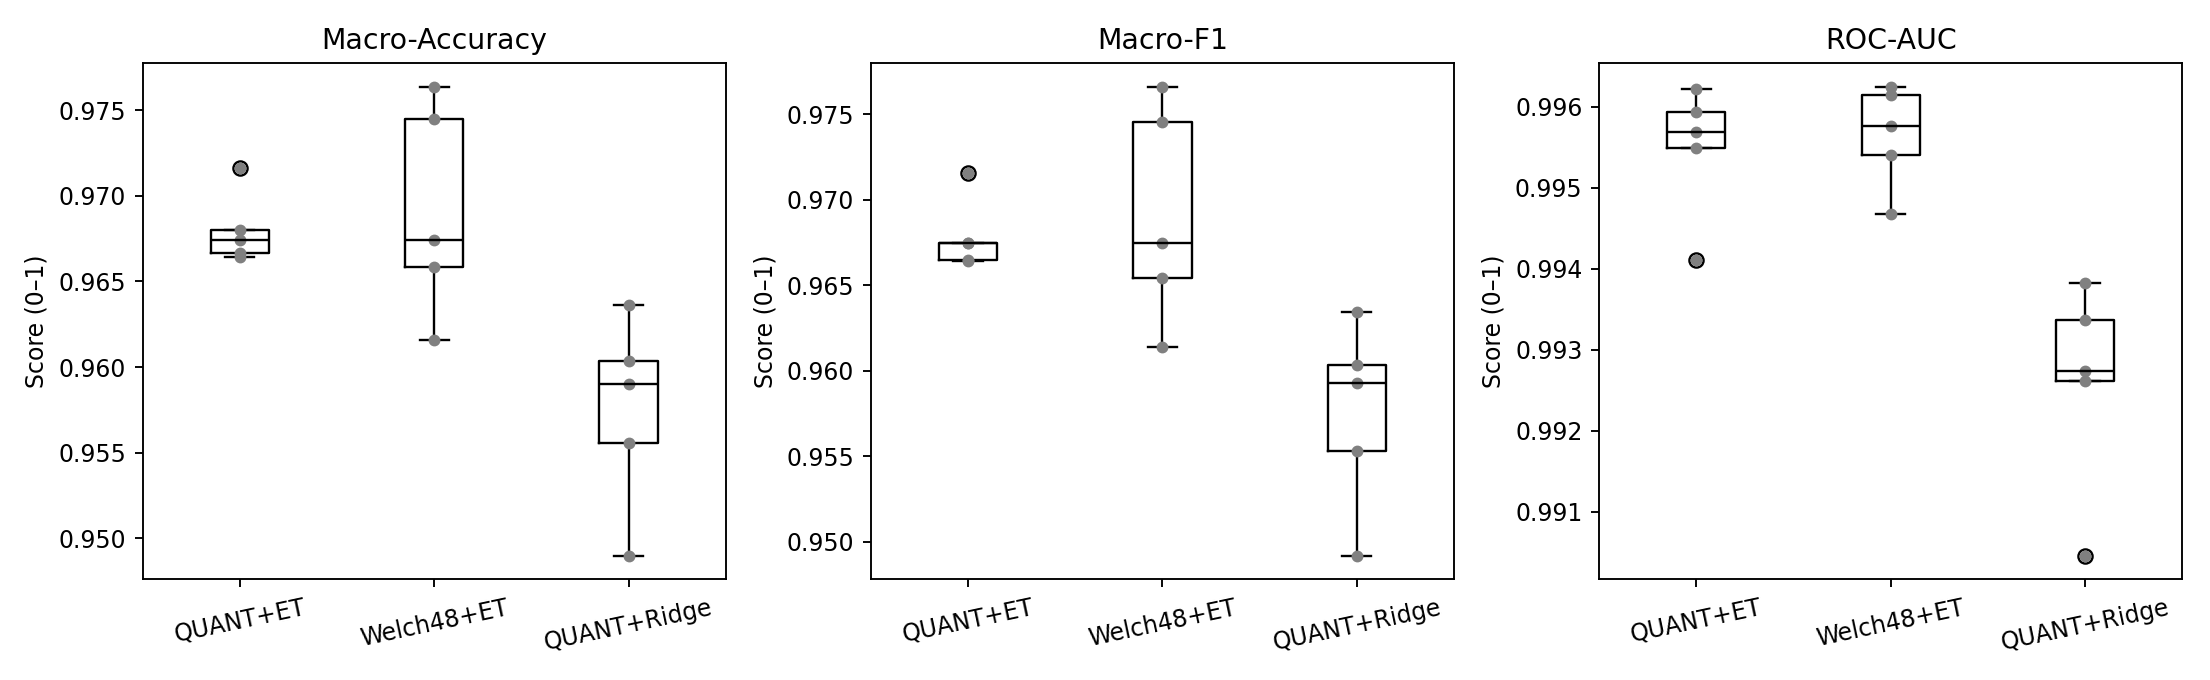

**boxplot_per_class.png**

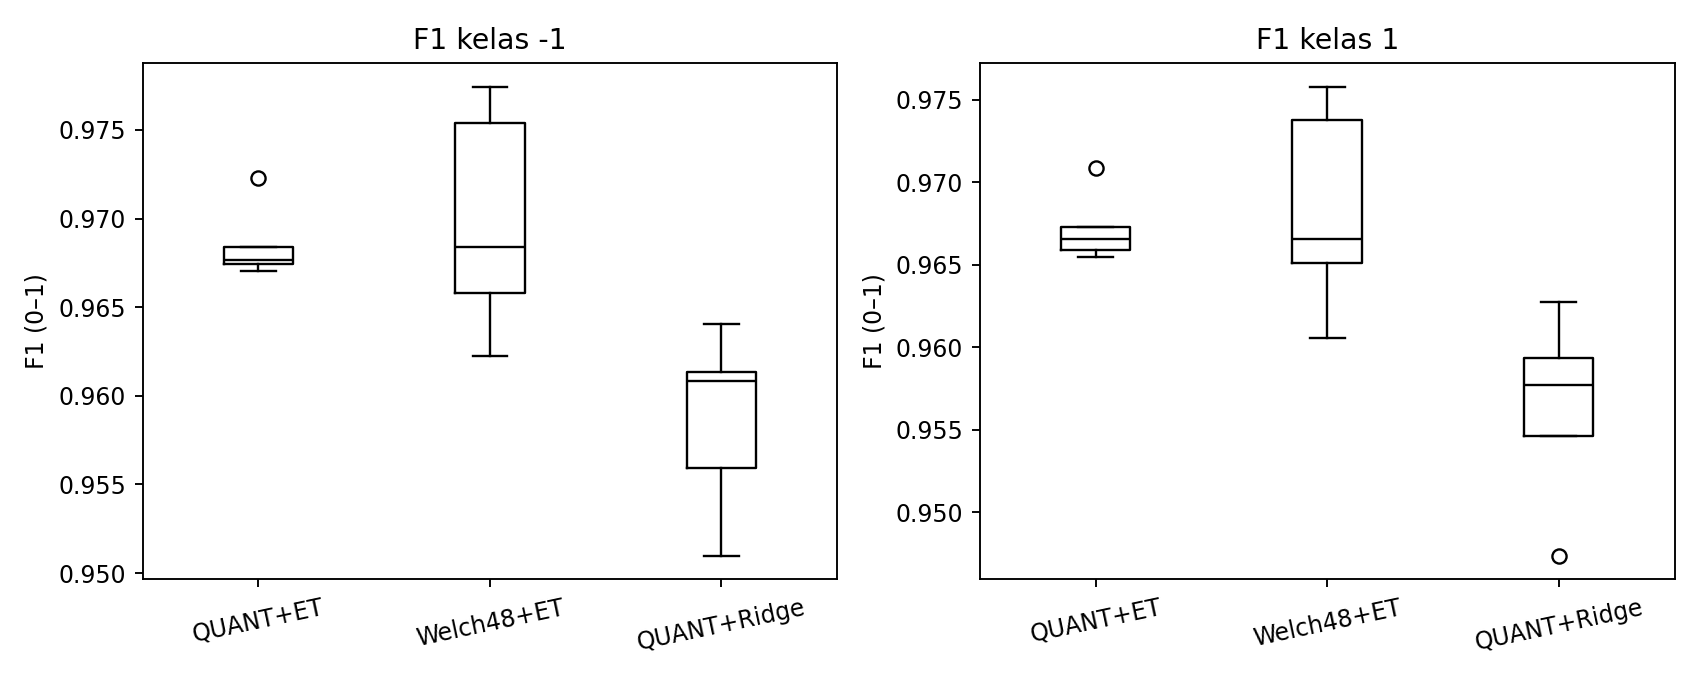

**confusion_oof.png**

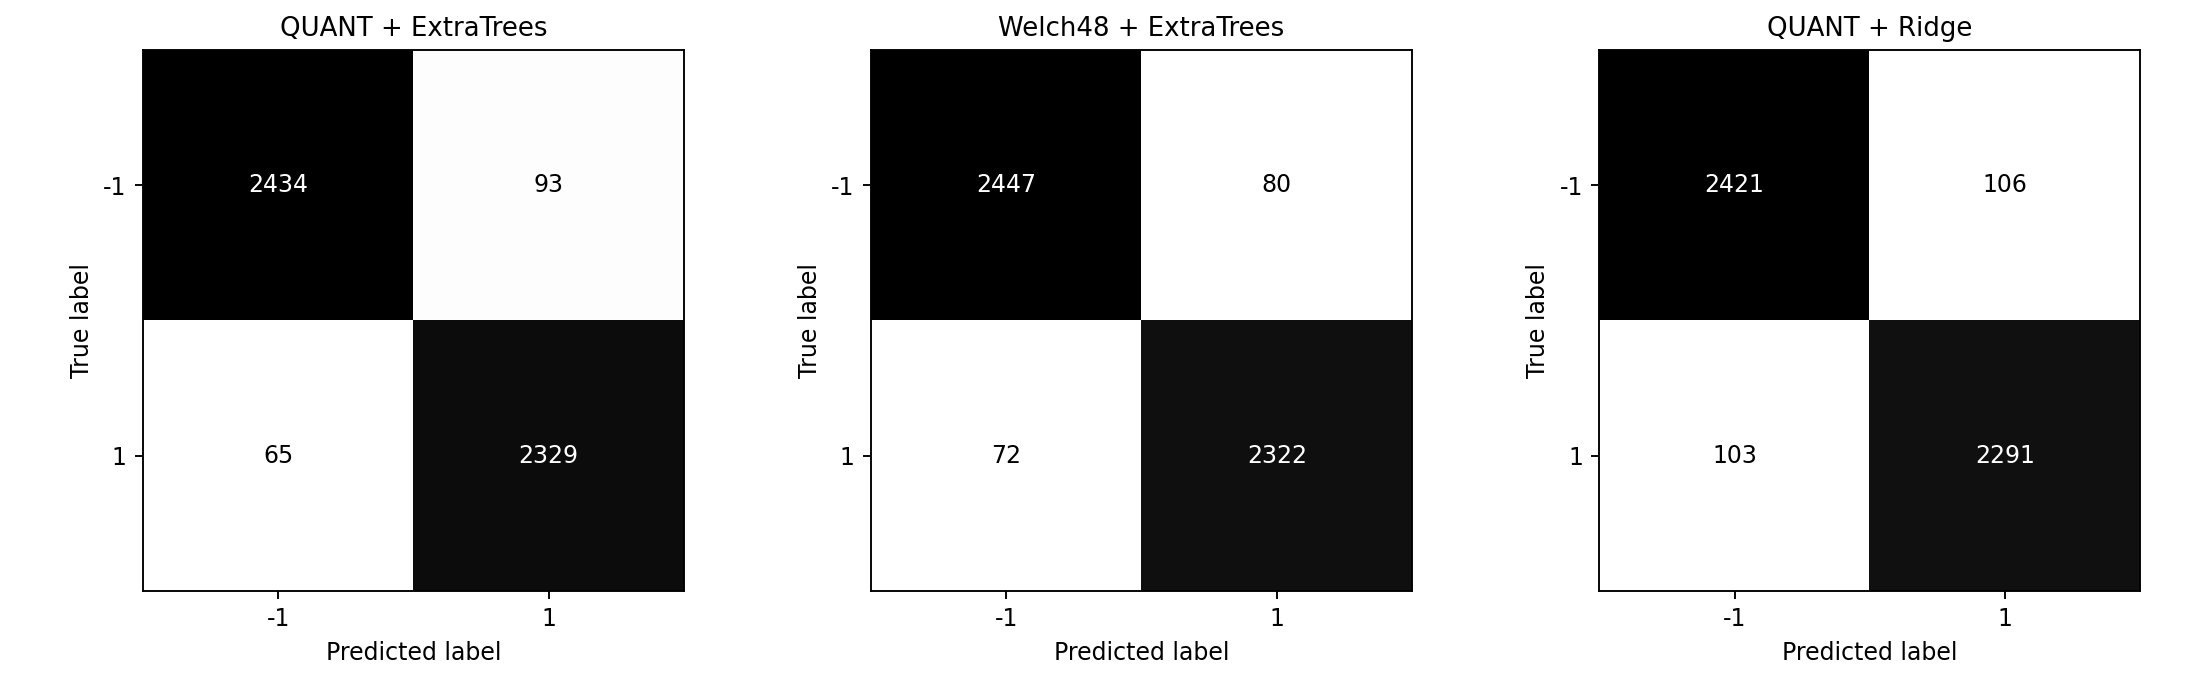

**roc_multifold.png**

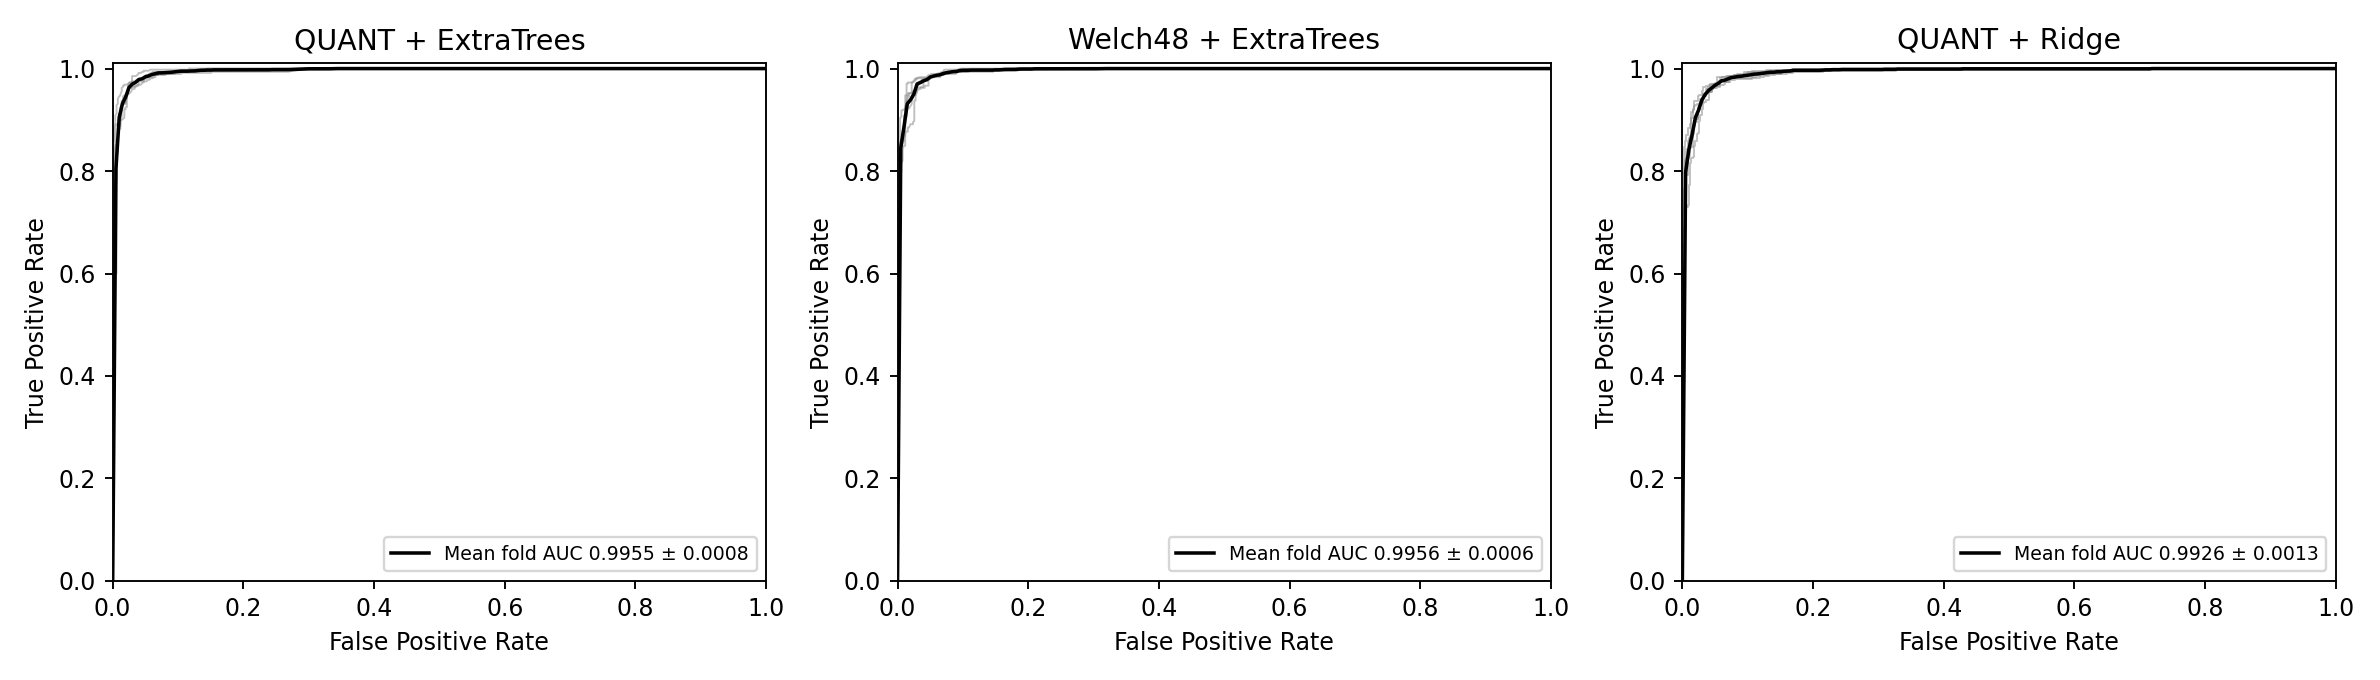

**learning_curve_internal.png**

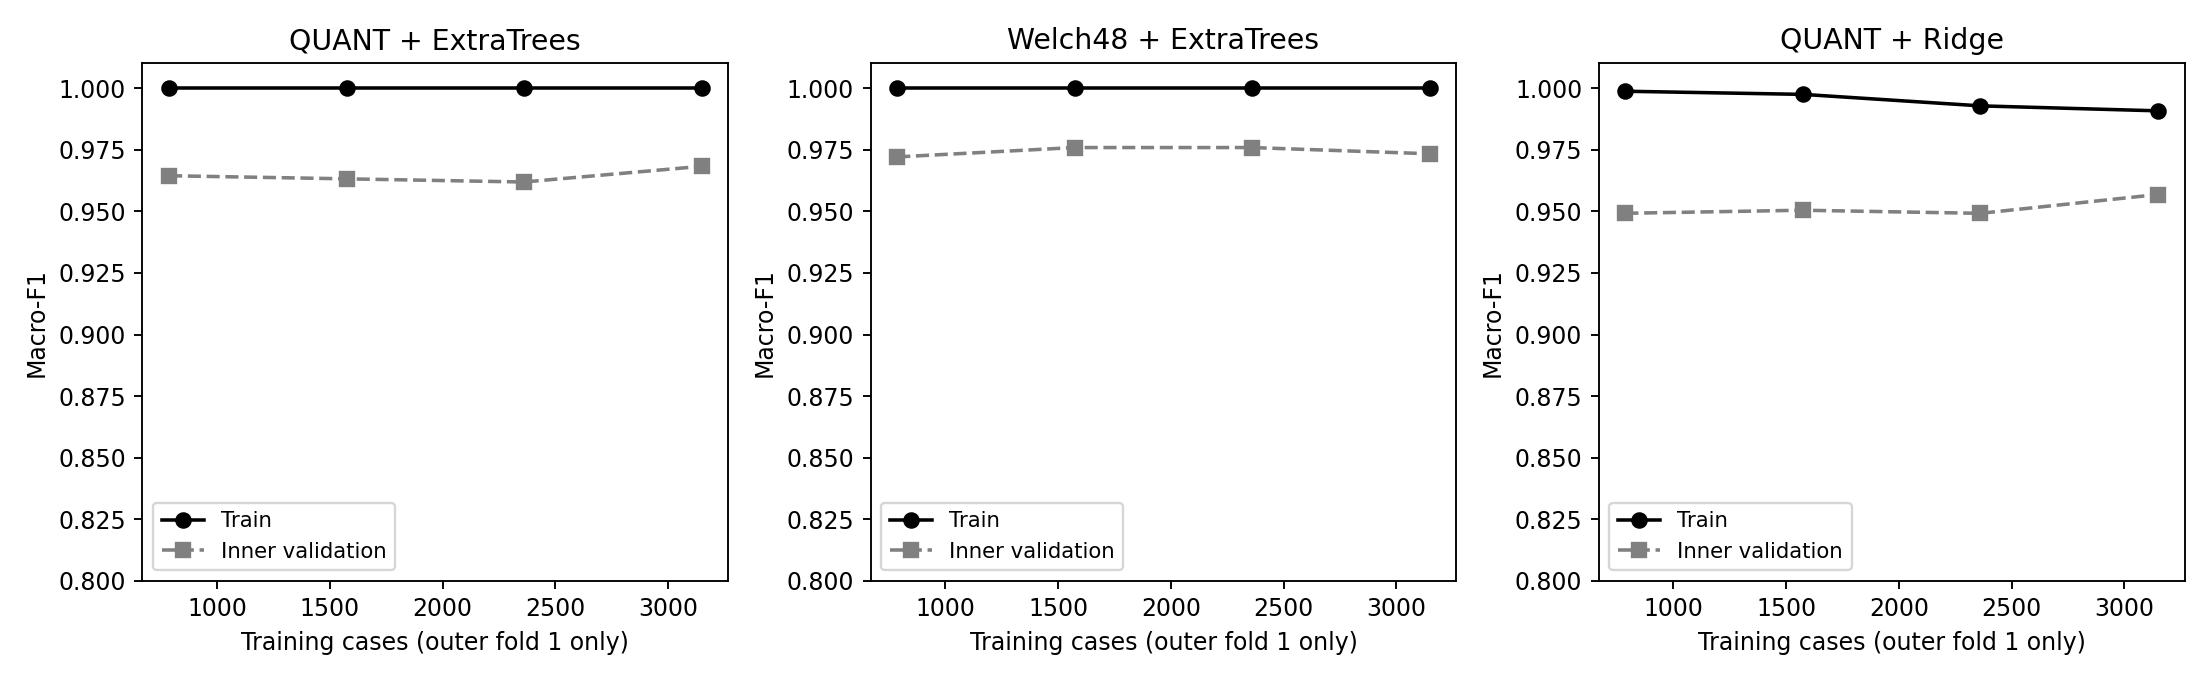

In [7]:
for name in ['boxplot_metrics.png','boxplot_per_class.png','confusion_oof.png','roc_multifold.png','learning_curve_internal.png']:
    display(Markdown('**'+name+'**'))
    display(Image(filename=str(RUN/name)))

## 6. Analisis kesalahan

Label +1 dipakai sebagai kelas positif. FP berarti label sebenarnya −1 diprediksi +1; FN berarti label sebenarnya +1 diprediksi −1. Tidak ada penamaan kerusakan fisik yang tidak didukung metadata.

Semua kesalahan tersimpan di errors.csv, lengkap dengan sumber kasus dan fold. Contoh grafik dipilih deterministik: dua FP dan dua FN pertama berdasarkan indeks global, jika tersedia, dari Welch48 (metode terbaik pada M2). Ini contoh untuk diperiksa, bukan bukti penyebab kerusakan atau sampel yang mewakili seluruh kesalahan.

|Metode|FP|FN|Total kesalahan|
|---|---:|---:|---:|
|QUANT + ExtraTrees|93|65|158|
|Welch48 + ExtraTrees|80|72|152|
|QUANT + Ridge|106|103|209|


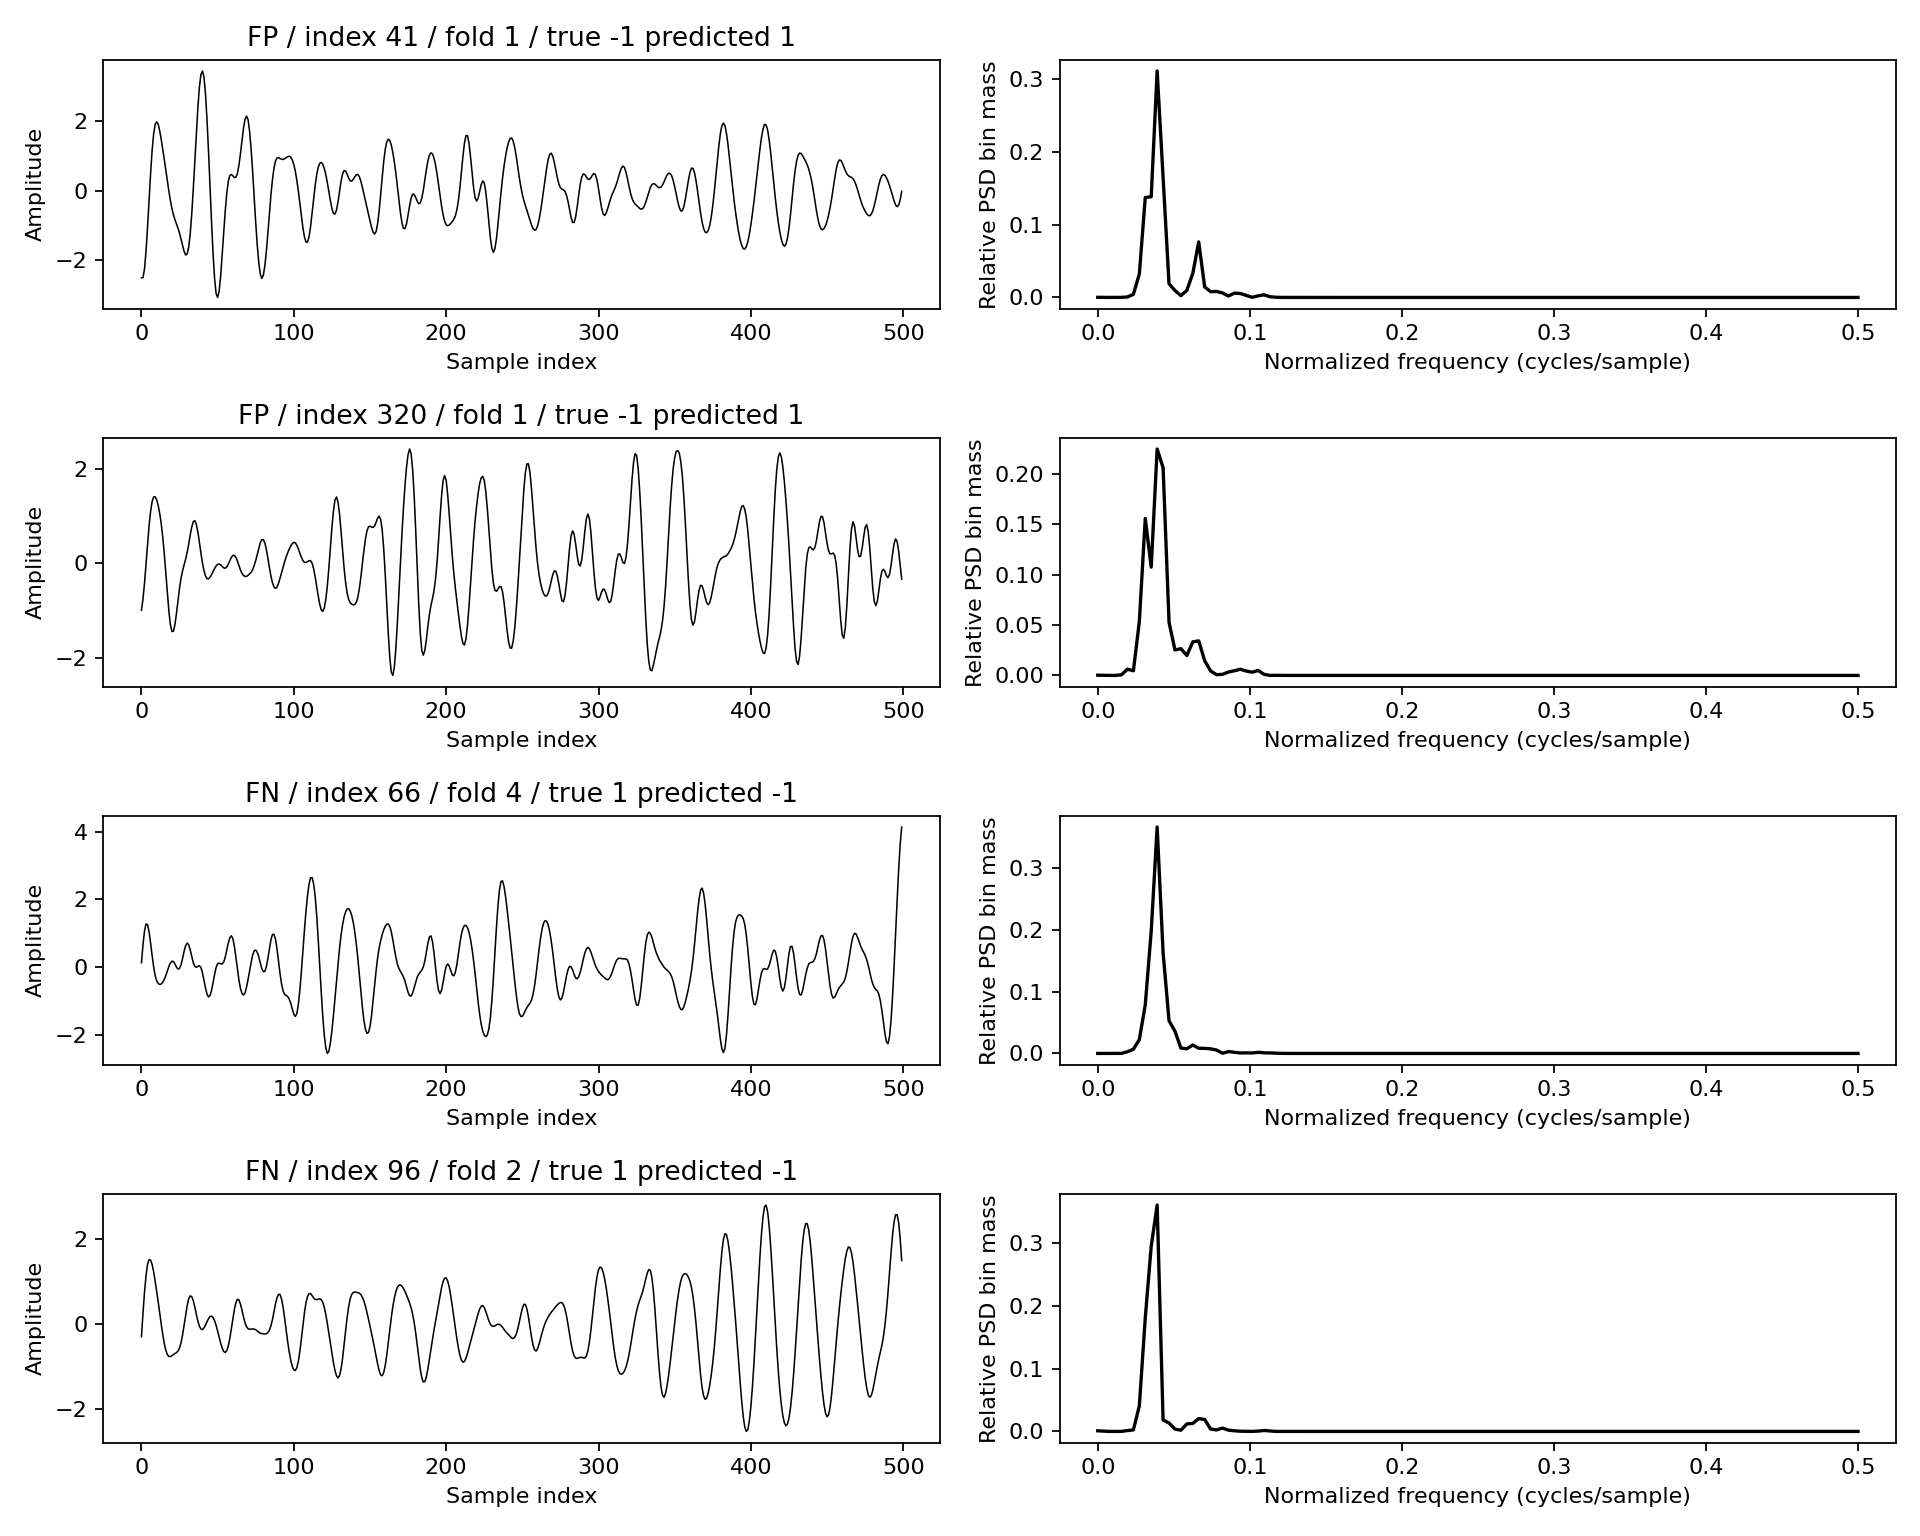

|Indeks global|Sumber kasus|Fold|Kesalahan|Label → prediksi|
|---:|---|---:|---|---|
|41|FordA_TRAIN.ts #42|1|FP|-1 → 1|
|320|FordA_TRAIN.ts #321|1|FP|-1 → 1|
|66|FordA_TRAIN.ts #67|4|FN|1 → -1|
|96|FordA_TRAIN.ts #97|2|FN|1 → -1|


In [8]:
table='|Metode|FP|FN|Total kesalahan|\n|---|---:|---:|---:|\n'
for r in result['error_summary']:table+='|{}|{}|{}|{}|\n'.format(names[r['method']],r['false_positive'],r['false_negative'],r['total_errors'])
display(Markdown(table))
if (RUN/'error_examples.png').is_file():display(Image(filename=str(RUN/'error_examples.png')))
examples=json.loads((RUN/'error_examples.json').read_text())['examples']
display(Markdown('|Indeks global|Sumber kasus|Fold|Kesalahan|Label → prediksi|\n|---:|---|---:|---|---|\n'+''.join('|{}|{} #{}|{}|{}|{} → {}|\n'.format(e['global_index'],e['source_file'],e['source_case_1based'],e['fold'],e['error_type'],e['y_true'],e['y_pred']) for e in examples)))

## 7. Kesimpulan dan artefak pengumpulan

Gunakan tabel mean ± SD bersama arah selisih dan p-value, bukan hanya skor tertinggi. Hasil satu dataset dan lima fold tidak membuktikan generalisasi ke kendaraan, mesin, atau sesi baru. Audit duplikat persis tidak menggantikan pemisahan berdasarkan kelompok sumber.

Artefak: config.json, environment.json, requirements.txt, requirements_actual.txt, execution.log, data_audit.json, feature_audit.json, folds.json, fold_metrics.csv, summary.csv, paired_tests.csv, results.json, model/prediksi per fold, prediksi OOF, grafik, dan errors.csv. Semuanya ada di folder RUN M3. M1/M2 tetap tersimpan terpisah.

In [9]:
best=max(result['summary'],key=lambda r:r['macro_f1_mean'])
print('Macro-F1 mean tertinggi pada run ini:',names[best['method']],f"{100*best['macro_f1_mean']:.2f}%")
print('Ini pemeringkatan deskriptif; gunakan tabel uji berpasangan untuk interpretasi perbedaan.')
print('Folder artefak:',RUN)
print('Run status:',json.loads((RUN/'run_status.json').read_text()))

Macro-F1 mean tertinggi pada run ini: Welch48 + ExtraTrees 96.91%
Ini pemeringkatan deskriptif; gunakan tabel uji berpasangan untuk interpretasi perbedaan.
Folder artefak: /content/drive/MyDrive/dsp_quant_forda/runs/m3_stratified5fold_seed42
Run status: {'status': 'complete', 'complete': True, 'completed_fold_jobs': 15, 'total_fold_jobs': 15, 'learning_jobs': 12, 'new_fits_this_invocation': 27, 'cached_fits_this_invocation': 0, 'OOF_cases_per_method': 4921}


## Sumber

- [Paper QUANT](https://doi.org/10.1007/s10618-024-01036-9)
- [Kode penulis](https://github.com/angus924/quant)
- [FordA](https://www.timeseriesclassification.com/description.php?Dataset=FordA)
- [StratifiedKFold](https://scikit-learn.org/1.6/modules/generated/sklearn.model_selection.StratifiedKFold.html)
- [SciPy paired t-test](https://docs.scipy.org/doc/scipy-1.15.3/reference/generated/scipy.stats.ttest_rel.html)

Sumber transform, classifier, dan fitur M2 dipertahankan. M3 menambah protokol evaluasi serta analisis, bukan mengganti baseline.